# Problem Statement:
The rapid growth of urban transportation services and shared mobility systems has increased the importance of efficient bike rental management. Bike-sharing systems generate large amounts of daily usage data that can be analyzed to understand customer behavior and forecast future demand. Accurate prediction of bike rental counts helps operators optimize bike availability, improve customer satisfaction, reduce operational costs, and support sustainable urban transportation planning.

This project focuses on analyzing a bike rental dataset containing environmental, seasonal, and temporal information such as temperature, humidity, wind speed, weather conditions, holidays, weekdays, and seasons. The goal is to identify the key factors influencing bike rental demand and build a predictive model capable of estimating the daily number of bike rentals under different environmental and seasonal settings.

# Importing Libraries:

In [125]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
!pip install xgboost

# Loading Dataset:

In [126]:
day_data = pd.read_csv("day.csv")
hour_data = pd.read_csv("hour.csv")

In [127]:
day_data

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796


In [128]:
hour_data

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


# Domain Analysis:

The project belongs to the domain of Transportation Analytics and Machine Learning. Transportation analytics helps in analyzing bike rental data to identify usage patterns, seasonal trends, and environmental factors affecting bike demand. Machine learning techniques are used to build predictive models that can assist bike-sharing companies in forecasting daily bike rental counts accurately.

* Important environmental and seasonal attributes available in the dataset include:

   * Season
   * Year
   * Month
   * Holiday
   * Weekday
   * Working day
   * Weather condition
   * Temperature
   * Feeling temperature
   * Humidity
   * Wind speed

* The target column in this project is cnt, which is used to identify the total daily bike rental count.

* The dataset contains both numerical and categorical environmental features that help analyze bike rental demand under different seasonal and weather conditions.

* The prediction system helps bike-sharing companies estimate daily rental demand in advance and manage bike availability efficiently. It supports transportation planners in better resource allocation, demand forecasting, and operational decision-making.

* Benefits of the System:

   * Accurate prediction of daily bike rental demand
   * Better bike inventory management
   * Improved customer satisfaction
   * Efficient transportation planning
   * Reduced operational costs
   * Better understanding of seasonal and weather impacts on rentals
   * Support for sustainable and smart urban transportation systems

# Exploratory Data Analysis (EDA):

### 1. Initial Data Inspection:

In [129]:
day_data.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [130]:
day_data.tail()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796
730,731,2012-12-31,1,1,12,0,1,1,2,0.215833,0.223487,0.577500,0.154846,439,2290,2729


In [131]:
hour_data.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [132]:
hour_data.tail()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61
17378,17379,2012-12-31,1,1,12,23,0,1,1,1,0.26,0.2727,0.65,0.1343,12,37,49


#### Insights:
The initial inspection shows that both datasets are well-structured and contain relevant environmental, seasonal, and temporal features associated with bike rental demand. The day.csv dataset provides aggregated daily rental information for prediction modeling, while the hour.csv dataset contains detailed hourly records useful for additional behavioral and trend analysis.

### 2. Data Overview/Structure:

In [133]:
print(day_data.shape)
print(hour_data.shape)

(731, 16)
(17379, 17)


In [134]:
print(day_data.columns)
print(hour_data.columns)

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')
Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')


In [135]:
print(day_data.dtypes)
print(hour_data.dtypes)

instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


In [136]:
print(day_data.info())
print(hour_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns

#### Insights:
* The dataset contains multiple records and features related to environmental and seasonal conditions affecting bike rental demand.
* The dataset contains both numerical and categorical features suitable for machine learning and exploratory analysis.

### 3. Data Quality Checks:

In [137]:
print(day_data.isnull().sum())
print(hour_data.isnull().sum())

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [138]:
print(day_data.duplicated().sum())
print(hour_data.duplicated().sum())

0
0


#### Insights:
No missing values were found in the dataset, indicating good data quality for analysis and model building. Additionally No duplicate records were detected in the dataset, ensuring data consistency.

### 4. Statistical Summary:

In [139]:
day_data.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
season,731.0,2.496580,1.110807,1.000000,2.000000,3.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896


In [140]:
hour_data.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


#### Insights:
The statistical summary shows variation in environmental conditions and bike rental counts, indicating diverse rental patterns across different days.

### 5. Checking Unique Values in Categorical Features:

In [141]:
categorical_columns = ['season', 'yr', 'holiday',
                       'workingday', 'weathersit']

for col in categorical_columns:
    print(col)
    print(day_data[col].unique())
    print("------------------")

season
[1 2 3 4]
------------------
yr
[0 1]
------------------
holiday
[0 1]
------------------
workingday
[0 1]
------------------
weathersit
[2 1 3]
------------------


#### Insights:
The categorical features are properly encoded into distinct categories representing seasons, weather conditions, holidays, and working days.

### 6. Separating Numerical and Categorical Features:

In [142]:
numerical_columns = [
    'temp',
    'atemp',
    'hum',
    'windspeed',
    'casual',
    'registered',
    'cnt'
]

print("Numerical Features:")
print(numerical_columns)

Numerical Features:
['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [143]:
categorical_columns = [
    'season',
    'yr',
    'mnth',
    'holiday',
    'weekday',
    'workingday',
    'weathersit'
]

print("Categorical Features:")
print(categorical_columns)

Categorical Features:
['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']


#### Insights:
The dataset contains both categorical and numerical features. Categorical variables represent seasonal and weather-related categories, while numerical variables describe continuous environmental conditions and bike rental counts.

### 7. Univariate Analysis of Numerical Features:
  * Visualizing the shape of the distribution
  * Compact summary with emphasis on spread and outliers

#### 1. Distribution Plots of Numerical Features:

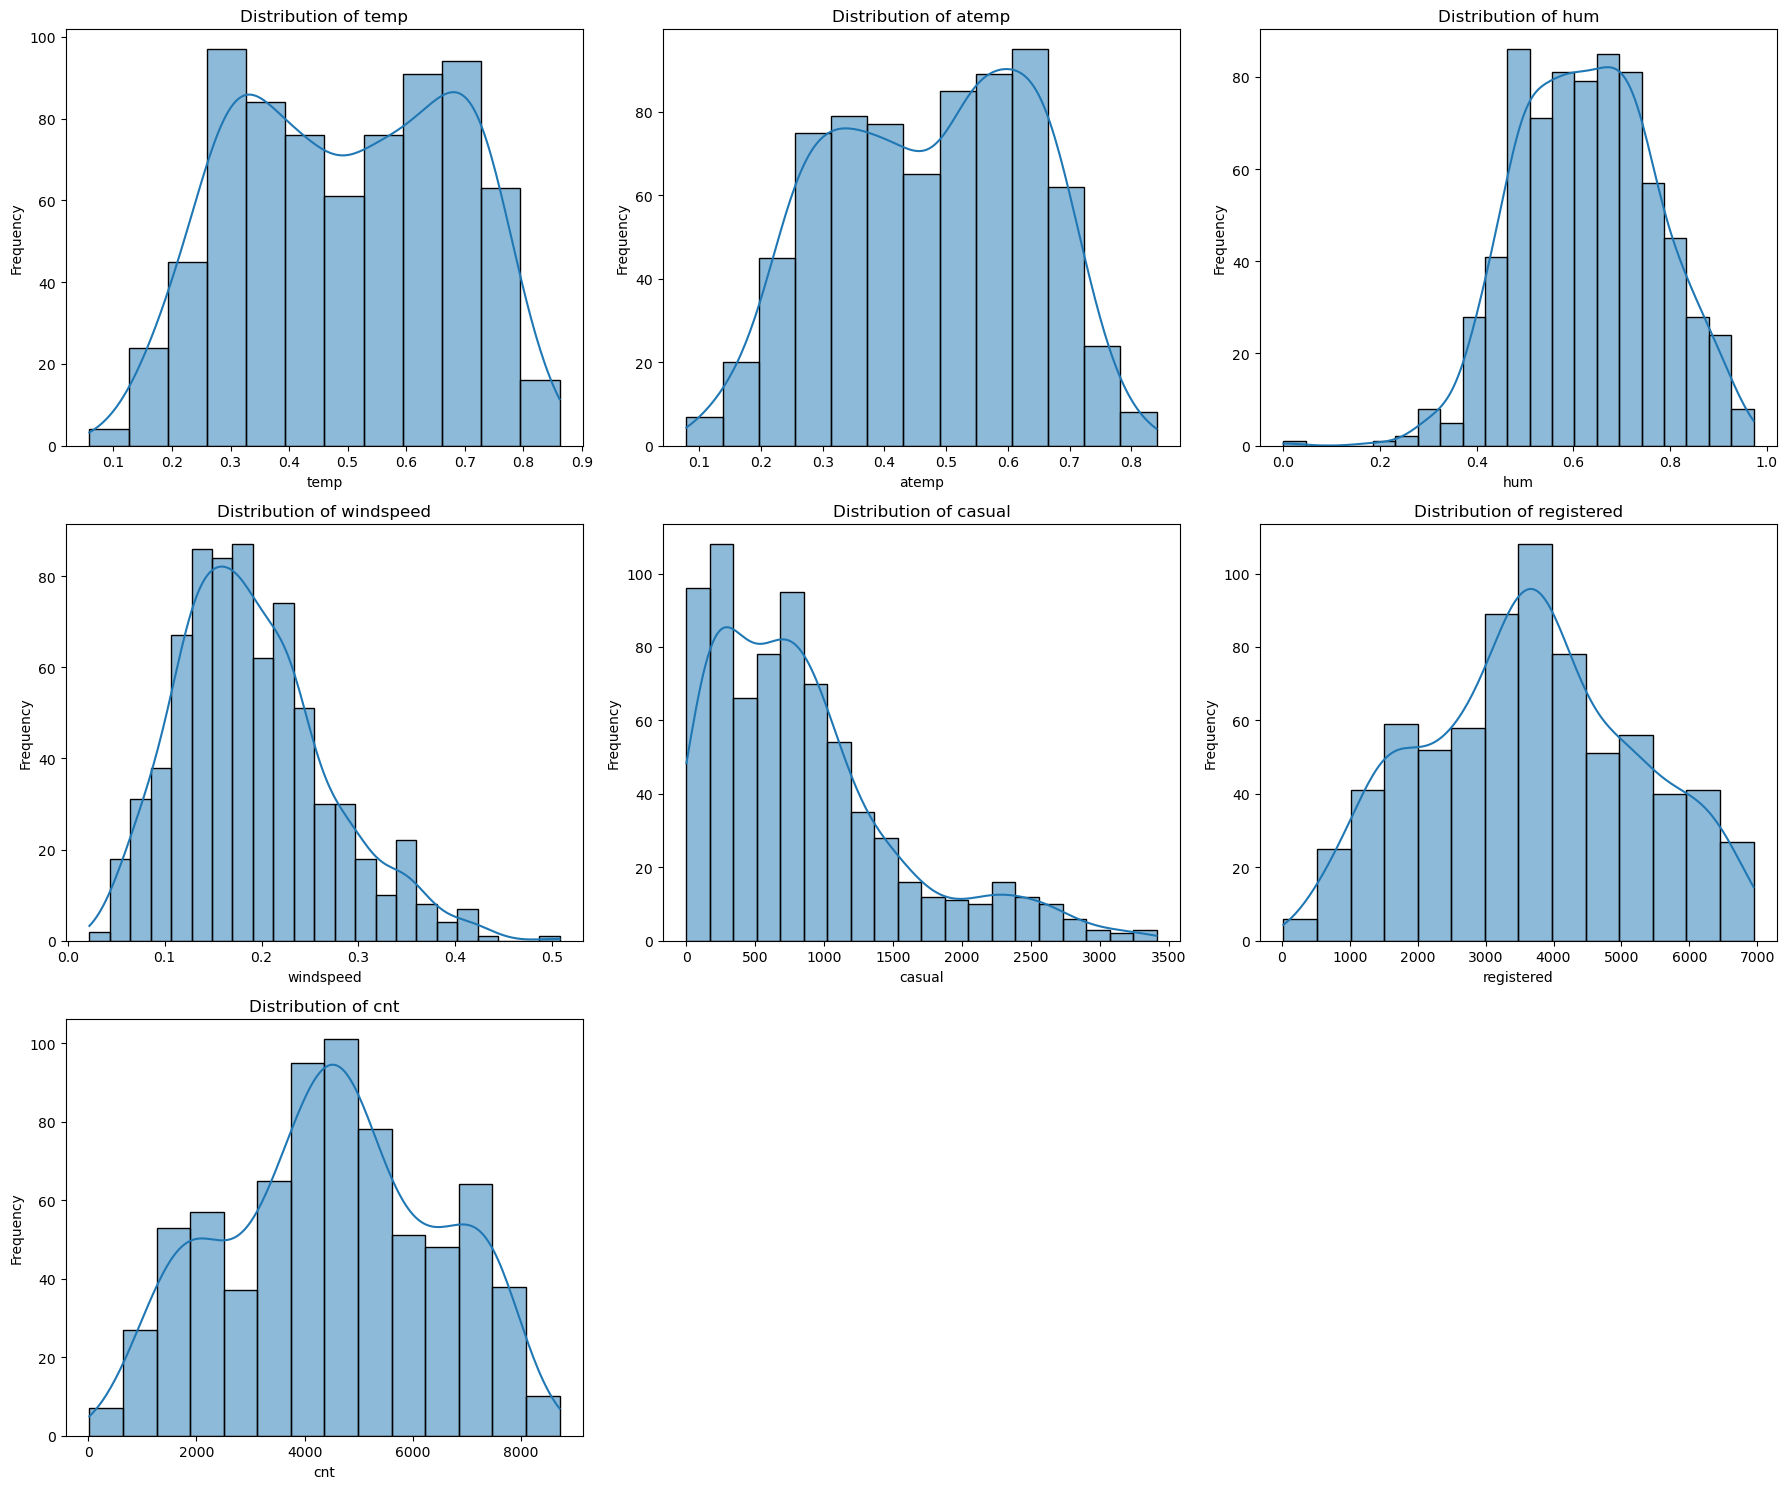

In [144]:
plt.figure(figsize=(18,15))

for i, col in enumerate(numerical_columns, 1):
    
    plt.subplot(3, 3, i)
    
    sns.histplot(day_data[col], kde=True)
    
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

#### Insights:
* The numerical features exhibit different distribution patterns, indicating variability in environmental conditions and bike rental activity.

* Temperature and feeling temperature values are concentrated within moderate ranges, suggesting that bike rentals are more common during comfortable weather conditions.

* Humidity values are moderately distributed, showing that bike rentals occur under varying moisture conditions.

* The wind speed feature appears positively skewed, indicating that lower wind speeds are more common while higher wind speed conditions occur less frequently.

* The casual, registered, and cnt variables show wider distributions and slight skewness, reflecting fluctuations in daily bike rental demand and user activity.

#### 2. Boxplots of Numerical Features:

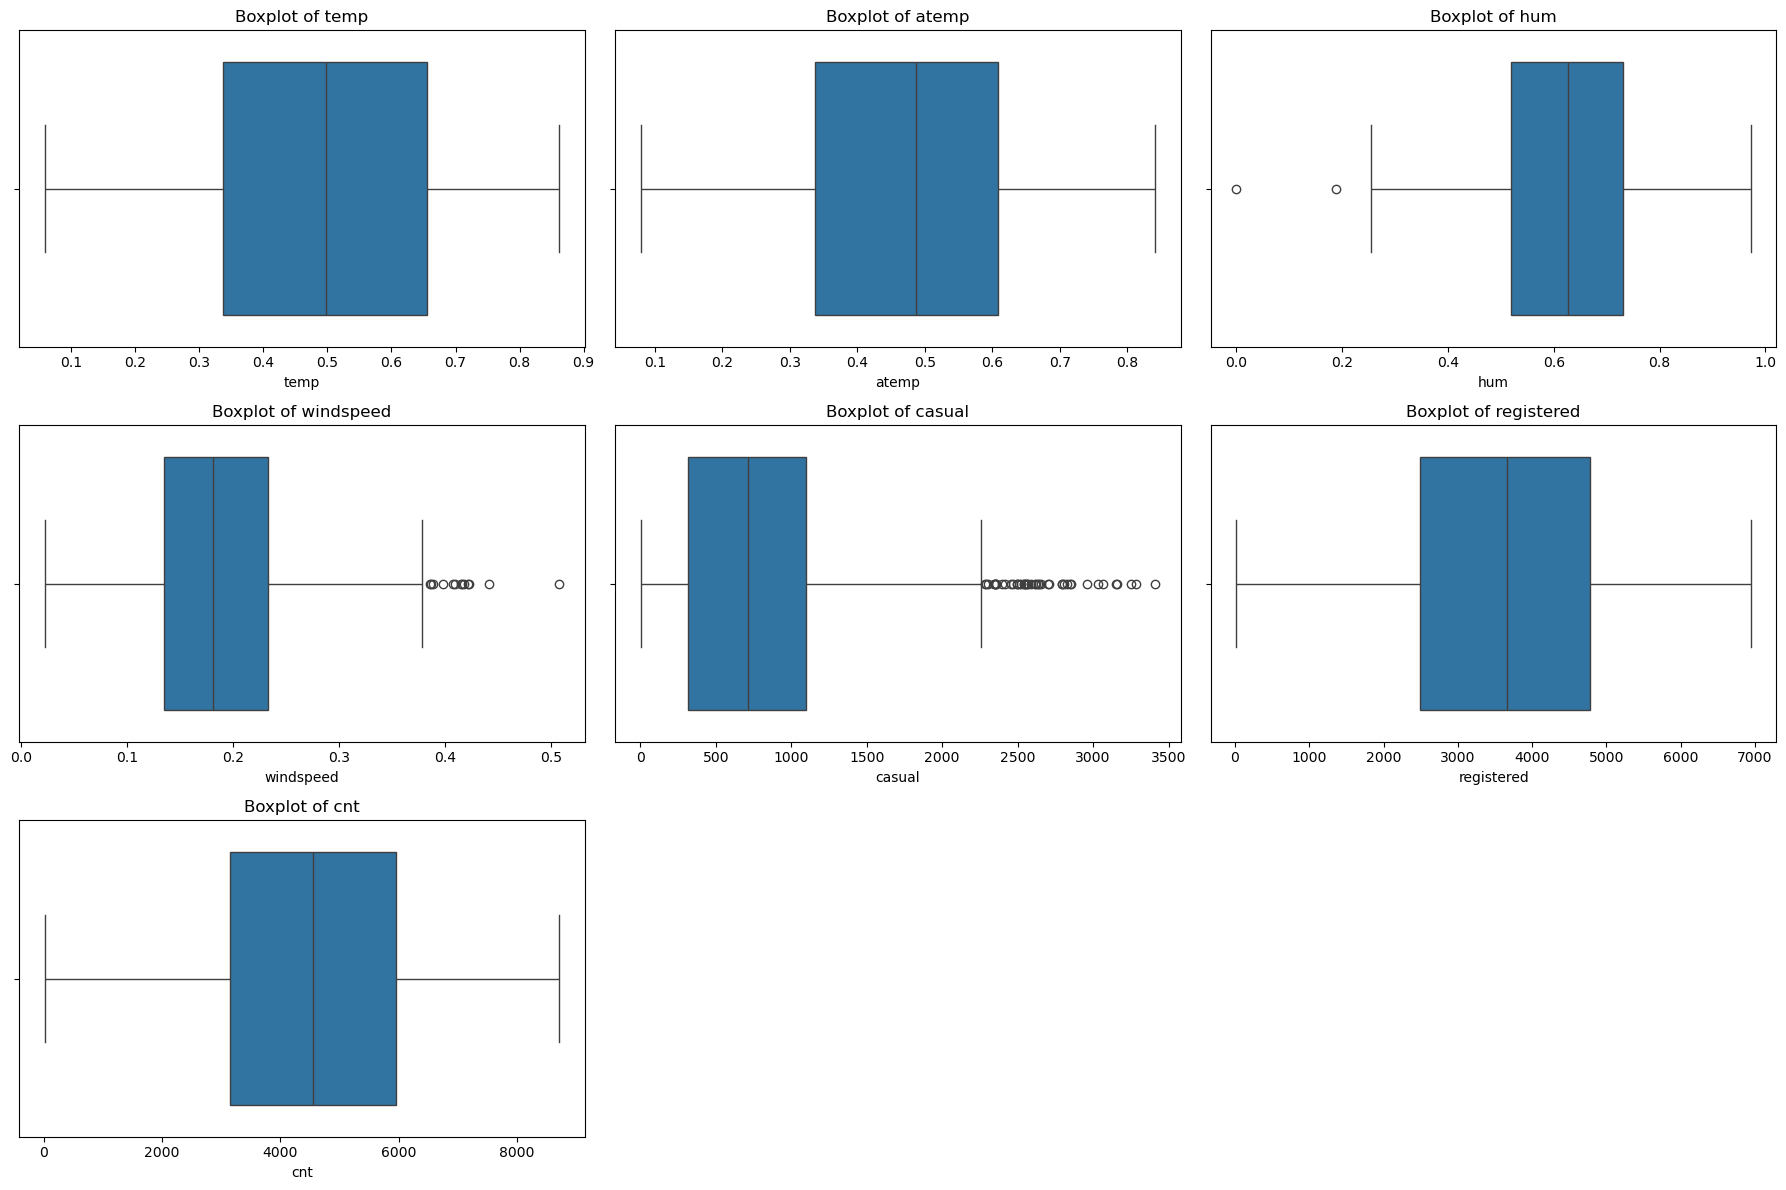

In [145]:
plt.figure(figsize=(18,12))

for i, col in enumerate(numerical_columns, 1):
    
    plt.subplot(3, 3, i)
    sns.boxplot(x=day_data[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

#### Insights:
* The boxplots reveal the presence of outliers in several numerical features, especially in bike rental count variables.

* Features such as casual, registered, and cnt show high variability, indicating significant differences in bike rental demand across days.

* Environmental variables like temperature and humidity display comparatively stable ranges with fewer extreme observations.

* The wind speed feature contains noticeable outliers, suggesting the occurrence of a few days with unusually high wind conditions.

* The spread of rental-related features indicates that environmental and seasonal factors strongly influence user rental behavior.

#### Reason for Not Applying Log Transformation:

* Although some numerical features exhibit slight skewness, the distributions are not extremely skewed and remain reasonably interpretable for analysis and machine learning models.

* The dataset does not contain severe distributional imbalance that would significantly affect model performance.

* Tree-based machine learning algorithms such as Decision Tree and Random Forest are generally less sensitive to skewed data distributions.

* Preserving the original scale of the variables helps maintain interpretability of environmental and rental-related features during analysis.

* Therefore, log transformation was not applied, as the existing feature distributions were considered acceptable for exploratory data analysis and predictive modeling.

### 8. Bivariate Analysis Of Numerical Features:
* Shows the relationship between numerical features and the target variable (cnt).
* It helps identify how environmental conditions influence daily bike rental demand.

#### 1. Scatterplots Between Numerical Features and Bike Rental Count:

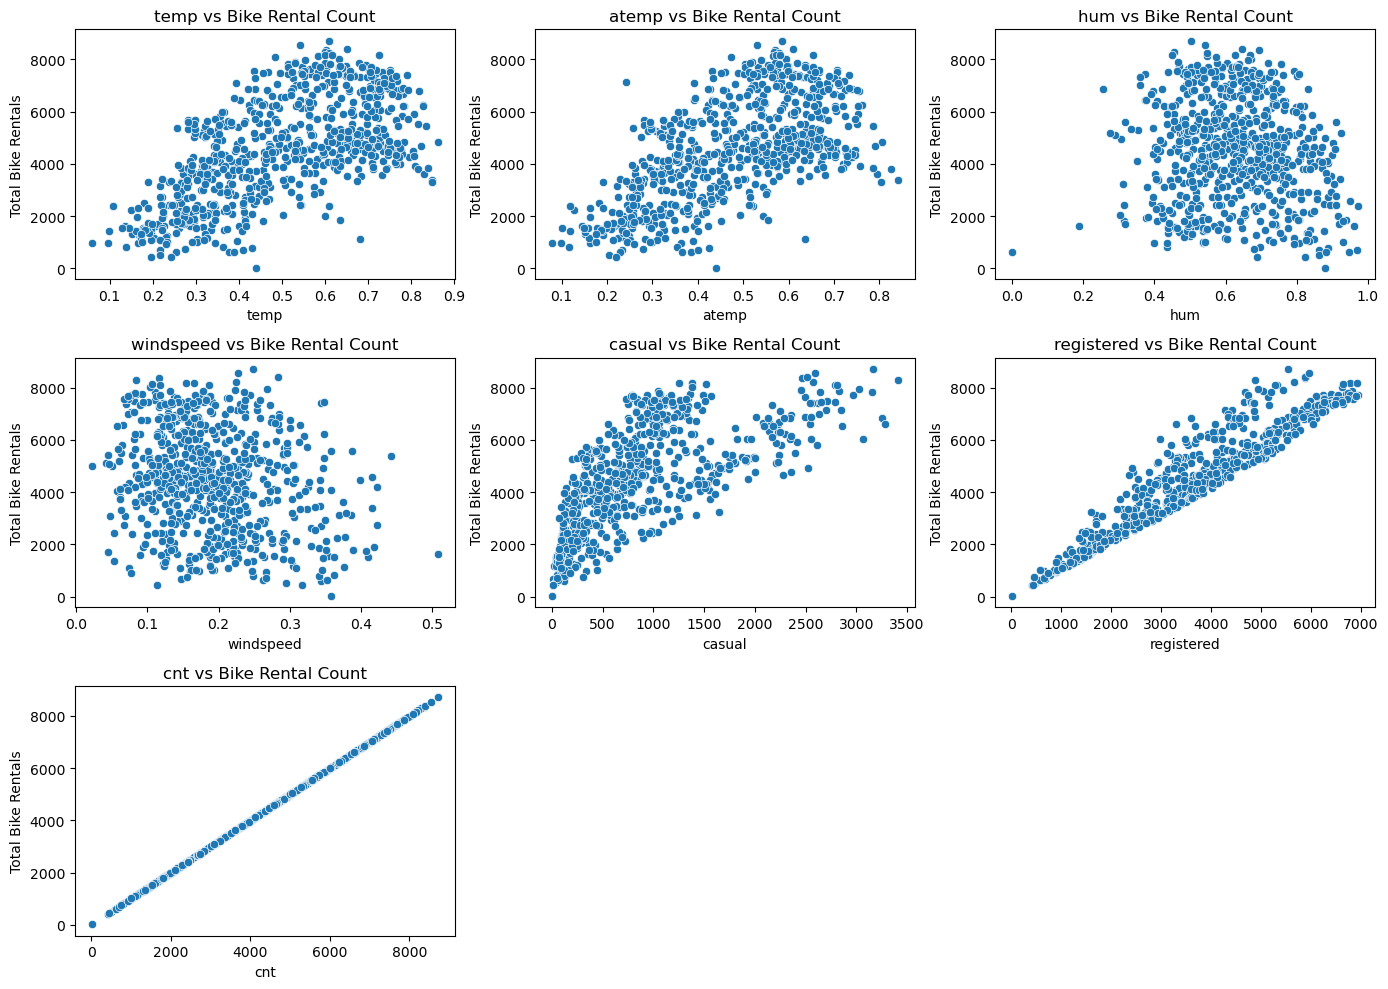

In [146]:
plt.figure(figsize=(14,10))

for i, col in enumerate(numerical_columns, 1):
    
    plt.subplot(3, 3, i)
    
    sns.scatterplot(x=day_data[col], y=day_data['cnt'])
    
    plt.title(f'{col} vs Bike Rental Count')
    plt.xlabel(col)
    plt.ylabel('Total Bike Rentals')

plt.tight_layout()
plt.show()

#### Insights:
* Temperature (temp) and feeling temperature (atemp) show a positive relationship with bike rental count, indicating increased rentals during favorable weather conditions.

* Humidity (hum) shows a slight negative relationship with bike rentals, suggesting that higher humidity may reduce user activity.

* Wind speed (windspeed) displays a weak negative relationship with bike rental demand, indicating reduced rentals during windy conditions.

* Registered users have a strong positive relationship with total rental count, showing that regular users contribute significantly to overall demand.

* Casual users also show a positive relationship with total rentals, although their rental patterns appear more variable compared to registered users.

#### 2. Correlation Matrix:

In [147]:
correlation_matrix = day_data[numerical_columns].corr()

correlation_matrix

,temp,atemp,hum,windspeed,casual,registered,cnt
temp,1.000000,0.991702,0.126963,-0.157944,0.543285,0.540012,0.627494
atemp,0.991702,1.000000,0.139988,-0.183643,0.543864,0.544192,0.631066
hum,0.126963,0.139988,1.000000,-0.248489,-0.077008,-0.091089,-0.100659
windspeed,-0.157944,-0.183643,-0.248489,1.000000,-0.167613,-0.217449,-0.234545
casual,0.543285,0.543864,-0.077008,-0.167613,1.000000,0.395282,0.672804
registered,0.540012,0.544192,-0.091089,-0.217449,0.395282,1.000000,0.945517
cnt,0.627494,0.631066,-0.100659,-0.234545,0.672804,0.945517,1.000000


#### Insights:
* Temperature and feeling temperature have strong positive correlations with bike rental count.

* Humidity and wind speed show negative correlations with rentals, indicating reduced demand under unfavorable weather conditions.

* Temperature and feeling temperature are highly correlated with each other due to their similar environmental characteristics.

* The correlation values suggest that environmental conditions play a significant role in predicting bike rental demand.

* Numerical features demonstrate meaningful relationships suitable for machine learning modeling.

#### 3. Correlation Heatmap:

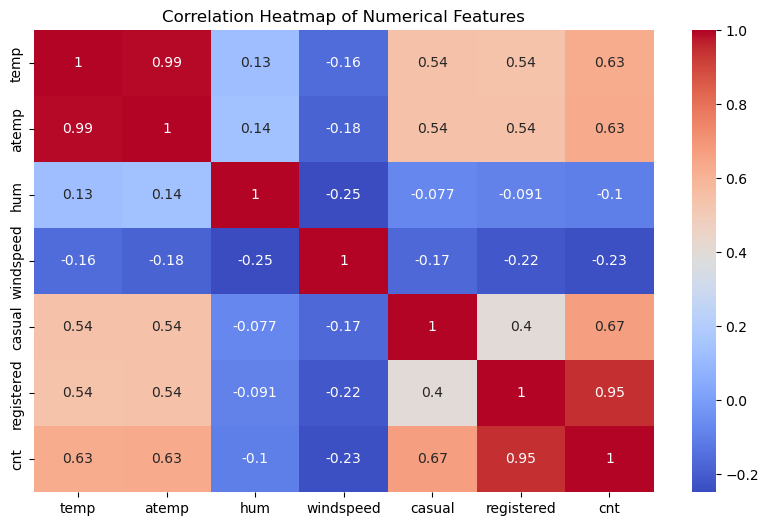

In [148]:
plt.figure(figsize=(10,6))

sns.heatmap(correlation_matrix,
            annot=True,
            cmap='coolwarm')

plt.title("Correlation Heatmap of Numerical Features")

plt.show()

#### Insights:
* Temperature (temp) and feeling temperature (atemp) have a strong positive correlation with bike rental count.

* Humidity (hum) and wind speed (windspeed) show negative correlations with rentals, indicating that unfavorable weather conditions may reduce bike usage.

* Registered users exhibit the strongest positive correlation with total rental count, highlighting their major contribution to bike-sharing demand.

* Casual users also positively influence total rentals, though their contribution is comparatively lower than registered users.

* Temperature and feeling temperature are highly correlated with each other, indicating similarity between actual and perceived temperature measurements.

### 9. Multivariate Analysis of Numerical Features:
* Shows combined relationships among multiple numerical variables and understand how environmental and user-related factors collectively influence bike rental demand.

#### 1. Pairplot of Numerical Features:

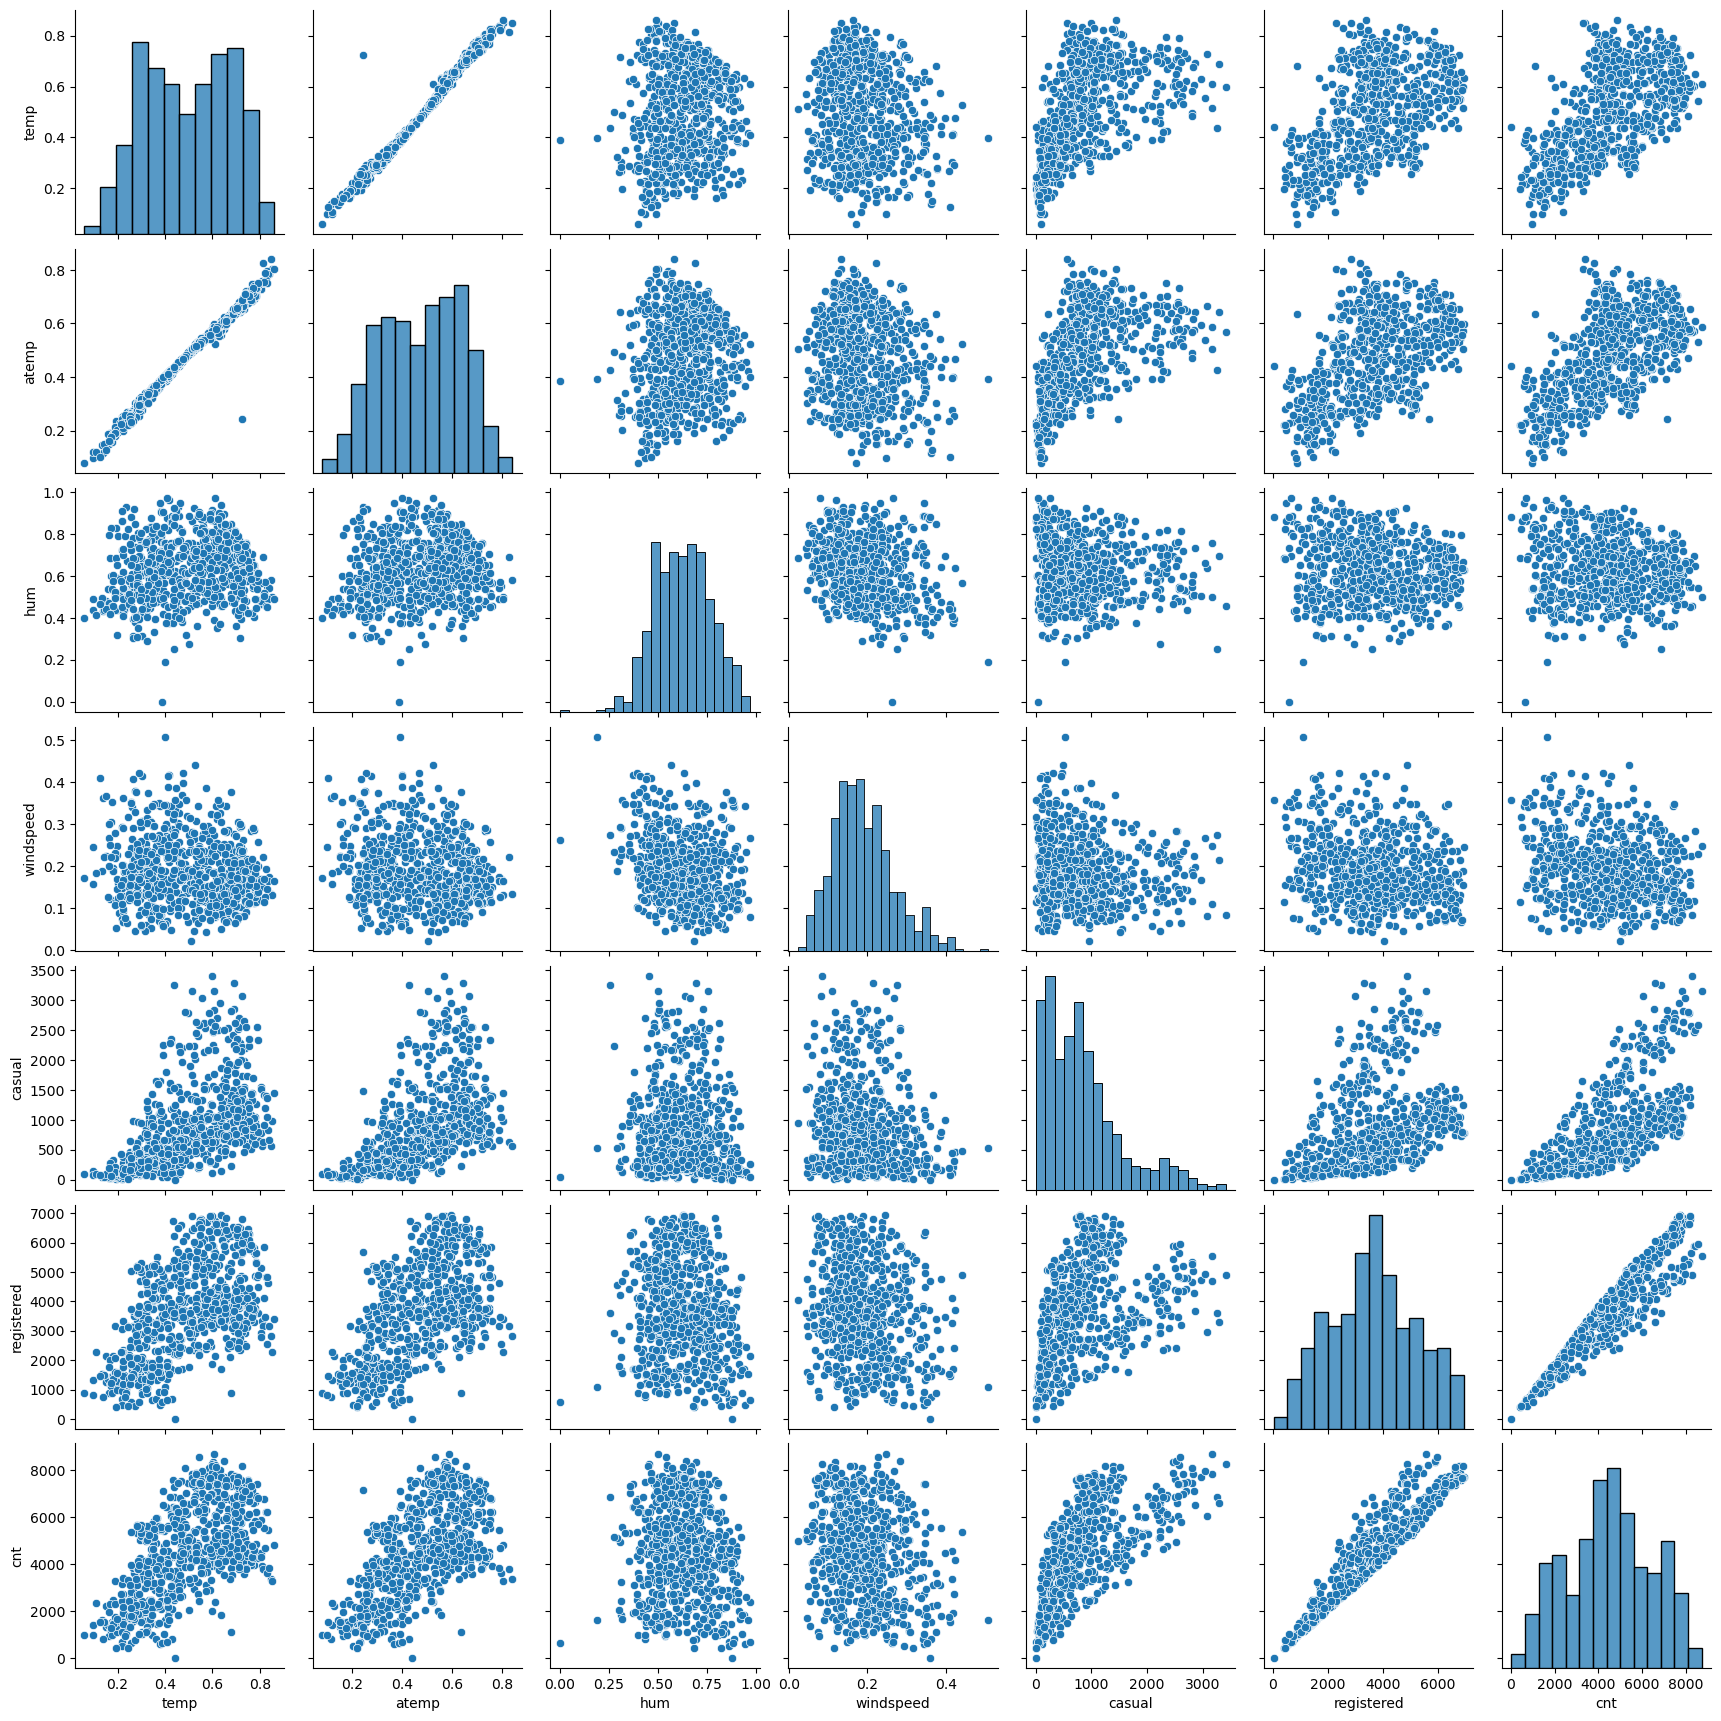

In [149]:
sns.pairplot(day_data[numerical_columns])

plt.show()

#### Insights:
* Temperature (temp) and feeling temperature (atemp) exhibit a strong positive relationship, indicating that perceived temperature increases along with actual temperature.

* Both temperature-related features show positive associations with total bike rental count (cnt), suggesting that favorable weather conditions encourage bike usage.

* Humidity (hum) demonstrates a slight negative relationship with bike rentals, indicating that higher humidity may reduce rental demand.

* Wind speed (windspeed) appears weakly negatively correlated with rental count, suggesting that extremely windy conditions may discourage users from renting bikes.

* Registered users show a very strong positive relationship with total bike rentals, highlighting that regular users contribute significantly to overall demand.

* Casual users also positively influence rental counts, although their rental behavior appears more variable compared to registered users.

* Several relationships among the variables display nonlinear patterns and varying data density, indicating that advanced machine learning models may better capture the complexity of bike rental behavior.

### 10. Univariate Analysis Of Categorical Features:
* Shows the distribution and frequency of different categories present in the dataset.

#### 1. Countplots of Categorical Features:

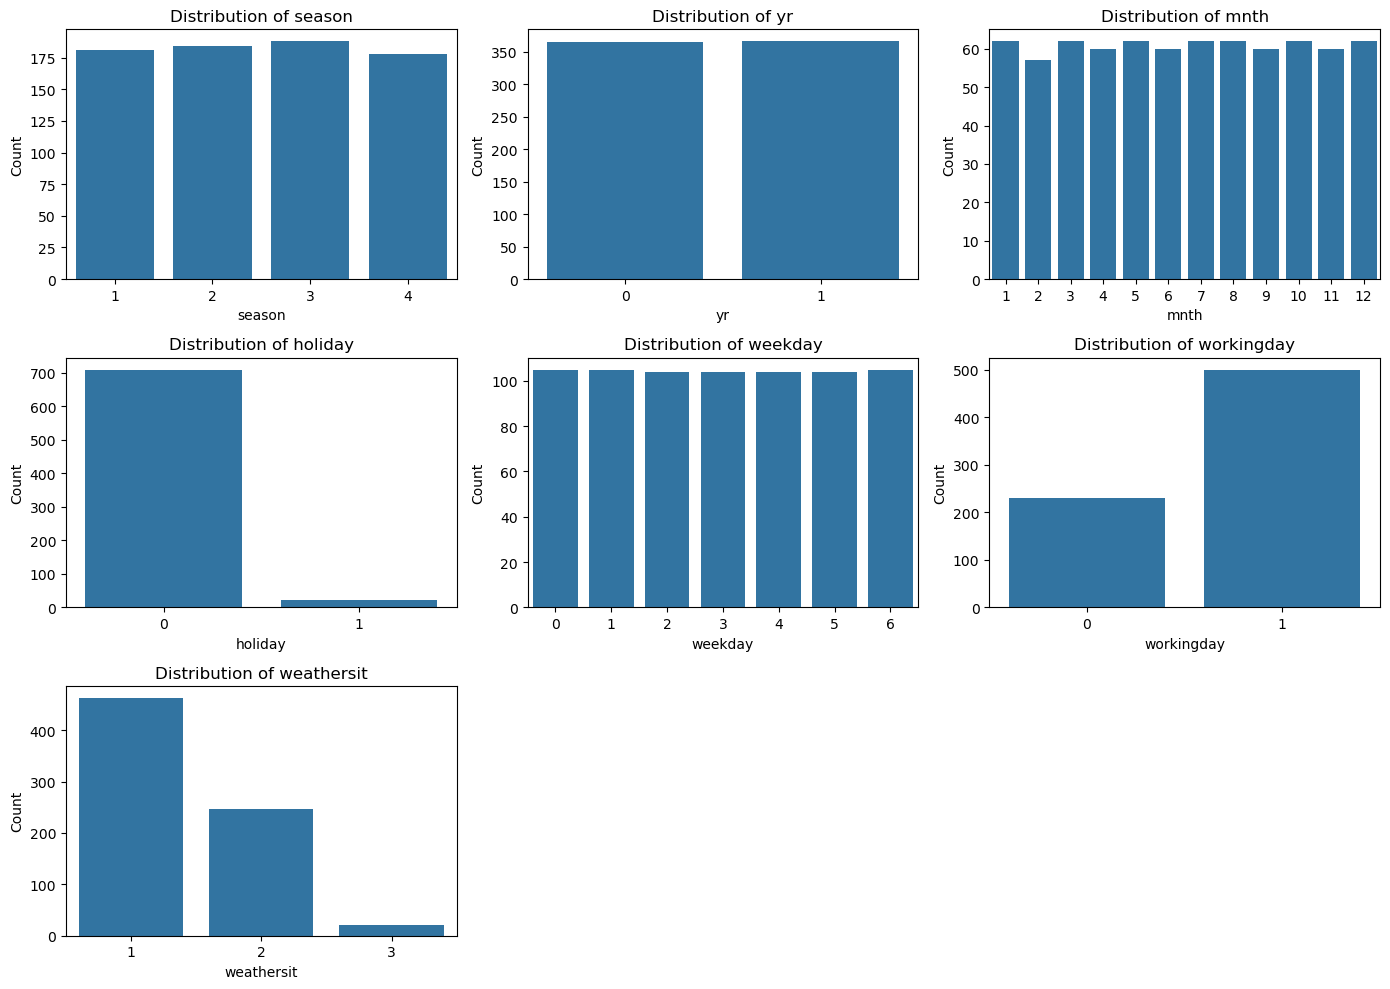

In [150]:
plt.figure(figsize=(14,10))

for i, col in enumerate(categorical_columns, 1):
    
    plt.subplot(3, 3, i)
    
    sns.countplot(x=day_data[col])
    
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

#### Insights:
* The dataset contains records from all four seasons, indicating balanced seasonal representation for analysis.

* Working days occur more frequently than holidays, suggesting that most observations belong to regular business days.

* Weather condition category 1 (clear or favorable weather) appears most frequently, indicating that most bike rentals occur under normal weather conditions.

* Weekday distribution is relatively balanced, ensuring representation of all days of the week in the dataset.

* Monthly distribution shows that bike rental observations are spread across different months, supporting seasonal and environmental analysis.

#### 2. Analysis of Season Distribution:

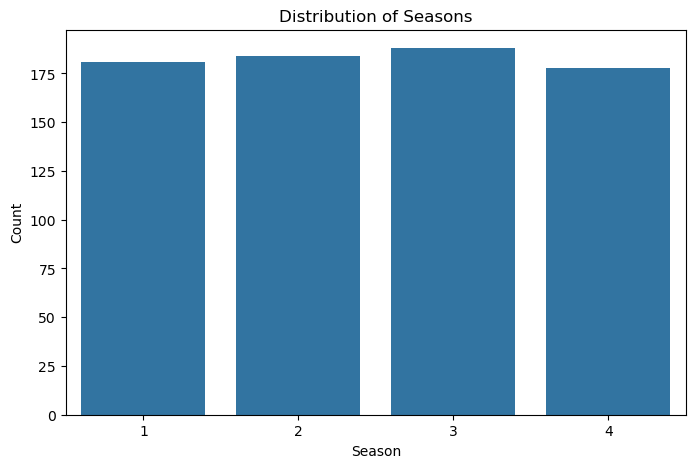

In [151]:
plt.figure(figsize=(8,5))

sns.countplot(x='season', data=day_data)

plt.title('Distribution of Seasons')
plt.xlabel('Season')
plt.ylabel('Count')

plt.show()

#### Insights:
* The dataset contains observations from all four seasons, enabling comprehensive seasonal analysis of bike rental demand.

* Certain seasons show slightly higher frequencies, indicating increased bike rental activity during favorable climatic conditions.

* Seasonal distribution helps analyze how weather and environmental changes influence user rental behavior over time.

#### 3. Analysis of Weather Conditions:

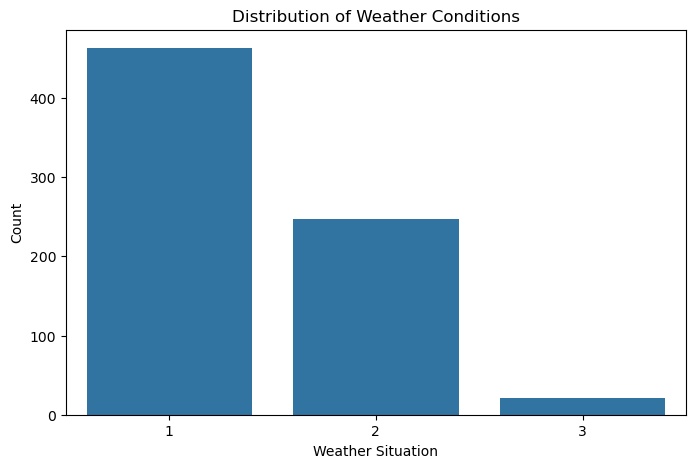

In [152]:
plt.figure(figsize=(8,5))

sns.countplot(x='weathersit', data=day_data)

plt.title('Distribution of Weather Conditions')
plt.xlabel('Weather Situation')
plt.ylabel('Count')

plt.show()

#### Insights:
* Favorable weather conditions occur most frequently in the dataset, indicating that bike rentals are commonly associated with clear or normal weather situations.

* Adverse weather conditions appear less frequently, suggesting reduced outdoor mobility during unfavorable climate conditions.

* The distribution of weather categories highlights the strong influence of environmental conditions on bike-sharing usage patterns.

#### 4. Analysis of Working Days:

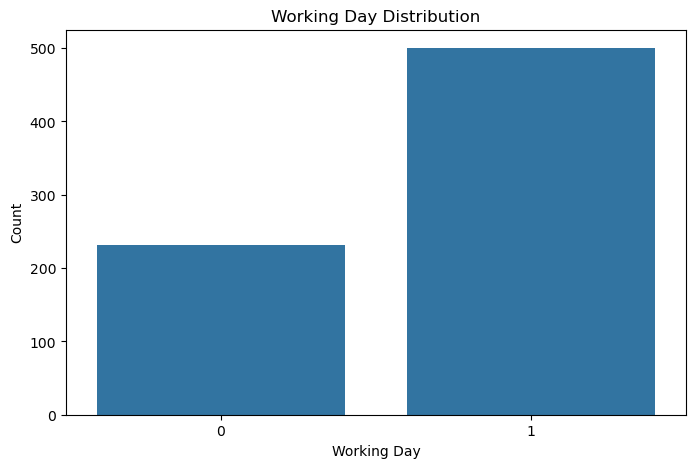

In [153]:
plt.figure(figsize=(8,5))

sns.countplot(x='workingday', data=day_data)

plt.title('Working Day Distribution')
plt.xlabel('Working Day')
plt.ylabel('Count')

plt.show()

#### Insights:
* Working days constitute a larger portion of the dataset compared to non-working days.

* Higher representation of working days suggests that bike rentals are frequently used for commuting and regular daily transportation.

* The balanced presence of both working and non-working days supports comparative analysis of user rental behavior across different day types.

#### 5. Analysis of Holidays:

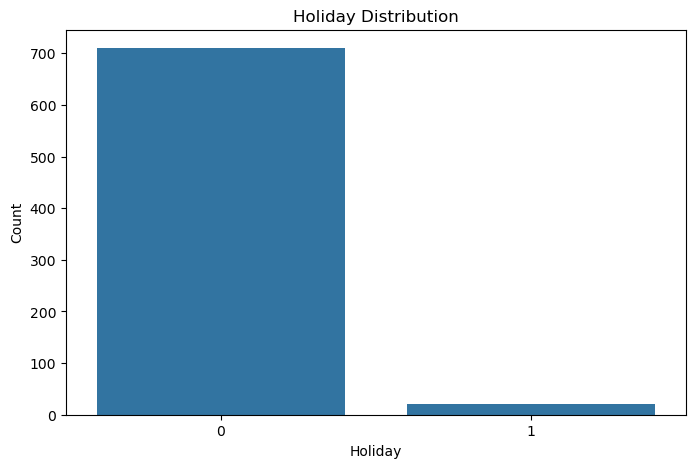

In [154]:
plt.figure(figsize=(8,5))

sns.countplot(x='holiday', data=day_data)

plt.title('Holiday Distribution')
plt.xlabel('Holiday')
plt.ylabel('Count')

plt.show()

#### Insights:
* Holidays occur less frequently in the dataset compared to regular non-holiday days.

* The lower number of holiday observations indicates that most rental activities are associated with routine daily schedules rather than holiday travel.

* Holiday analysis can help evaluate how special occasions and reduced work schedules affect bike rental demand patterns.

### 11. Bivariate Analysis of Categorical Features:
* Shows how different categorical variables influence the total bike rental count (cnt).

#### 1. Season vs Bike Rental Count:

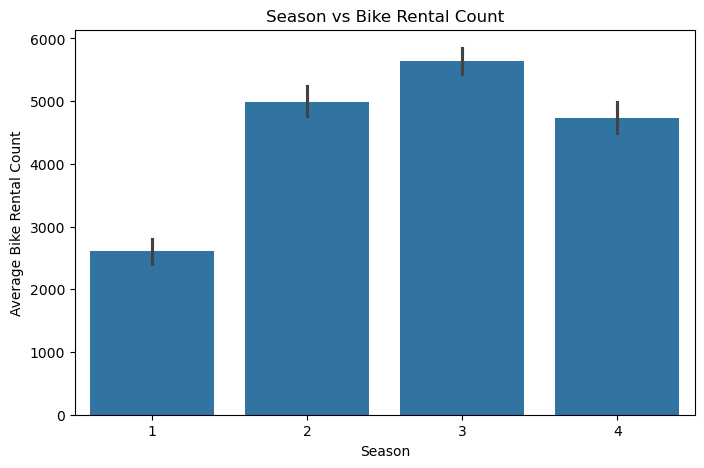

In [155]:
plt.figure(figsize=(8,5))

sns.barplot(x='season', y='cnt', data=day_data)

plt.title('Season vs Bike Rental Count')
plt.xlabel('Season')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Bike rental demand varies significantly across different seasons.

* Higher rental counts are observed during favorable weather seasons, indicating increased outdoor activity.

* Seasonal conditions play an important role in influencing bike-sharing usage patterns.

* Lower rentals during unfavorable seasons suggest reduced outdoor mobility under harsh environmental conditions.

#### 2. Weather Condition vs Bike Rental Count:

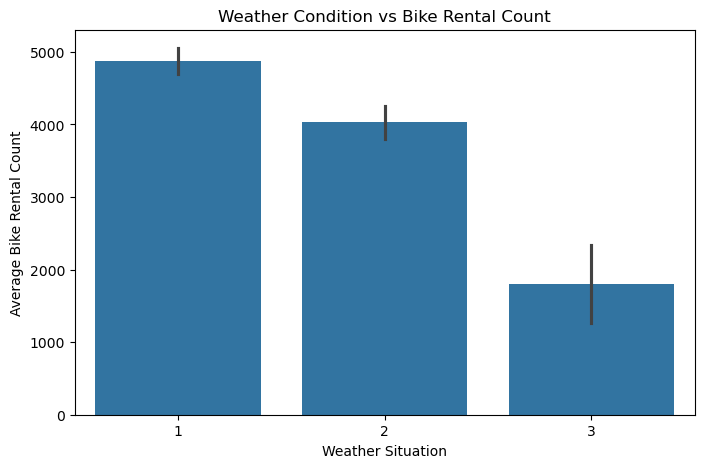

In [156]:
plt.figure(figsize=(8,5))

sns.barplot(x='weathersit', y='cnt', data=day_data)

plt.title('Weather Condition vs Bike Rental Count')
plt.xlabel('Weather Situation')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Clear and favorable weather conditions show higher bike rental demand compared to adverse weather situations.

* Rental activity decreases as weather conditions become unfavorable.

* Weather conditions significantly affect user willingness to rent bikes.

* Weather conditions play a crucial role in determining the daily demand for bike-sharing services.

#### 3. Working Day vs Bike Rental Count:

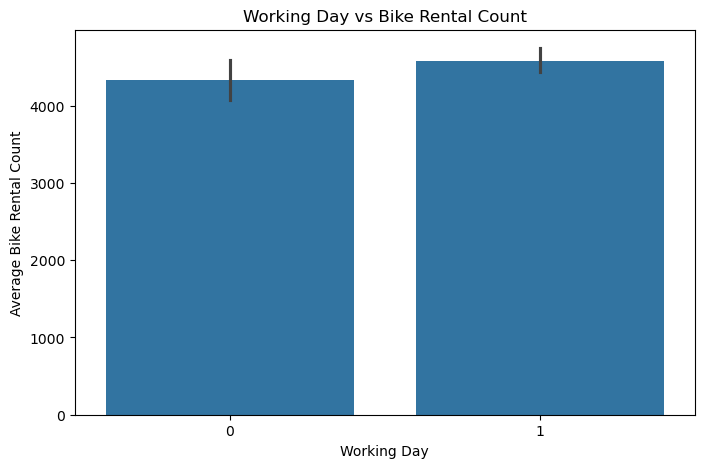

In [157]:
plt.figure(figsize=(8,5))

sns.barplot(x='workingday', y='cnt', data=day_data)

plt.title('Working Day vs Bike Rental Count')
plt.xlabel('Working Day')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Working days show considerable bike rental activity, indicating frequent use for commuting purposes.

* Rental demand remains relatively consistent across working and non-working days, though commuting behavior may differ.

* Bike-sharing systems are actively used for both professional and recreational purposes.

* Bike-sharing systems are widely utilized for both professional and personal travel needs.

#### 4. Holiday vs Bike Rental Count:

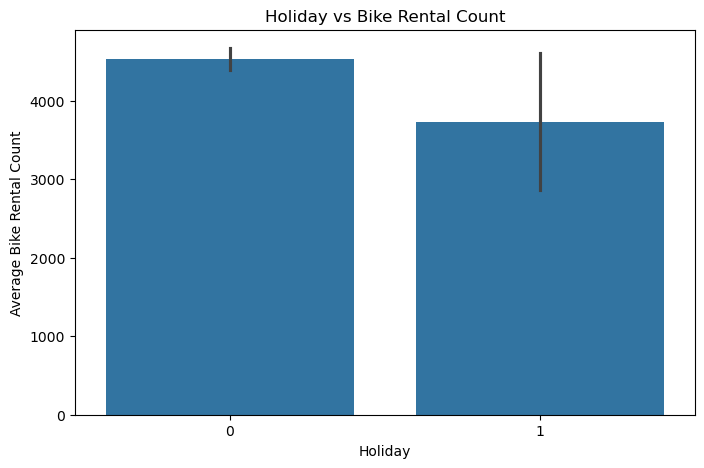

In [158]:
plt.figure(figsize=(8,5))

sns.barplot(x='holiday', y='cnt', data=day_data)

plt.title('Holiday vs Bike Rental Count')
plt.xlabel('Holiday')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Non-holiday days generally show higher bike rental demand compared to holidays.

* Reduced commuting activity during holidays may contribute to lower rental counts.

* Holiday status influences bike rental patterns and user travel behavior.

* The variation between holiday and non-holiday rentals indicates the importance of routine work schedules in bike-sharing usage.

#### 5. Weekday vs Bike Rental Count:

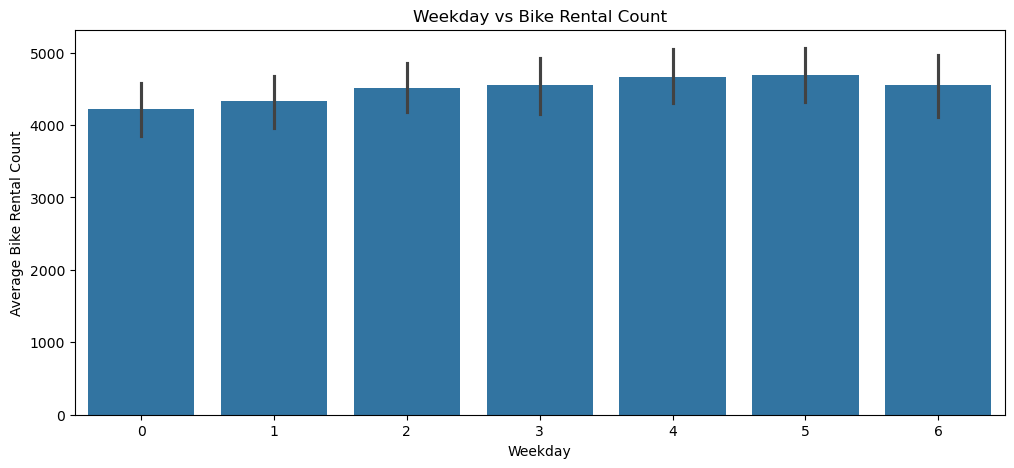

In [159]:
plt.figure(figsize=(12,5))

sns.barplot(x='weekday', y='cnt', data=day_data)

plt.title('Weekday vs Bike Rental Count')
plt.xlabel('Weekday')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Bike rental demand varies across different days of the week.

* Certain weekdays exhibit higher rental counts, possibly due to commuting and daily routine activities.

* Weekday analysis helps identify peak rental periods within the weekly cycle.

* Weekday analysis helps identify peak operational periods within the weekly rental cycle.

#### 6. Month vs Bike Rental Count:

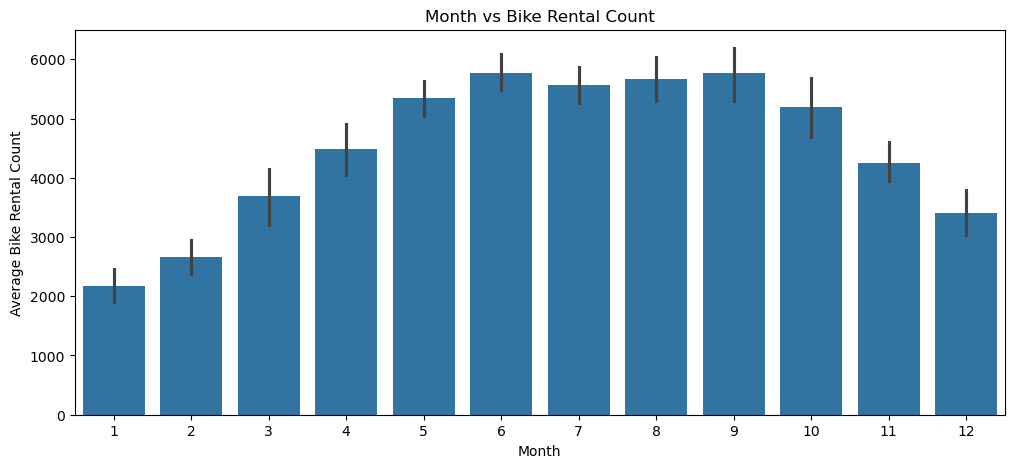

In [160]:
plt.figure(figsize=(12,5))

sns.barplot(x='mnth', y='cnt', data=day_data)

plt.title('Month vs Bike Rental Count')
plt.xlabel('Month')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Bike rental demand fluctuates across months, reflecting seasonal and climatic influences.

* Some months experience significantly higher rental activity, indicating favorable environmental conditions.

* Monthly trends help identify peak and low-demand rental periods throughout the year.

* Monthly analysis highlights long-term rental trends and helps identify high-demand periods.

#### 7. Year vs Bike Rental Count:

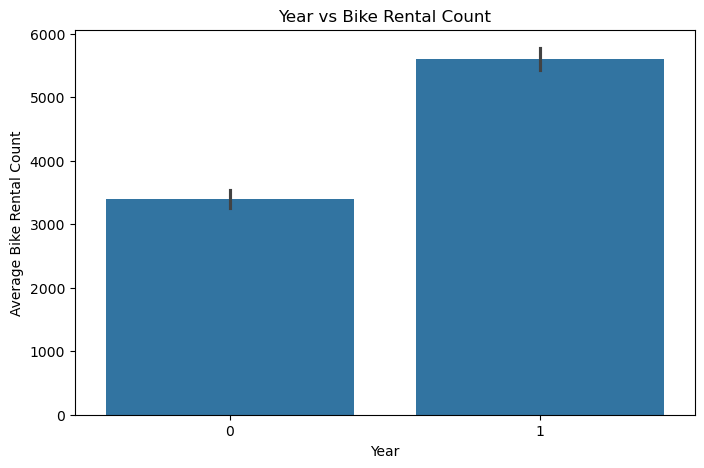

In [161]:
plt.figure(figsize=(8,5))

sns.barplot(x='yr', y='cnt', data=day_data)

plt.title('Year vs Bike Rental Count')
plt.xlabel('Year')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* The second year in the dataset shows increased bike rental demand compared to the first year.

* The growth in rentals may indicate rising popularity and adoption of bike-sharing services over time.

* Increased user engagement across years reflects expanding public acceptance of sustainable transportation systems.

* Year-wise growth trends suggest potential long-term development opportunities for bike-sharing operations.

### Overall Insights From Bivariate Analysis Of Categorical Features:
* Bike rental demand varies significantly across different seasons, indicating that seasonal conditions strongly influence user rental behavior.

* Favorable weather conditions result in higher average bike rentals, while adverse weather situations reduce rental activity considerably.

* Working days exhibit substantial rental demand, suggesting that many users rely on bike-sharing systems for commuting purposes.

* Non-holiday days generally show higher bike rental counts compared to holidays due to regular daily transportation activities.

* Monthly analysis reveals fluctuations in rental demand throughout the year, reflecting the impact of climatic and seasonal changes.

* Weekday-based variations indicate that user rental patterns differ across the weekly cycle, likely influenced by work schedules and recreational activities.

* The second year in the dataset demonstrates higher average rental counts, suggesting increased popularity and adoption of bike-sharing services over time.

### 12. Multivariate Analysis of Categorical Features:
* Shows how multiple categorical variables collectively influence bike rental demand (cnt).

#### 1. Season and Weather Condition vs Bike Rental Count:

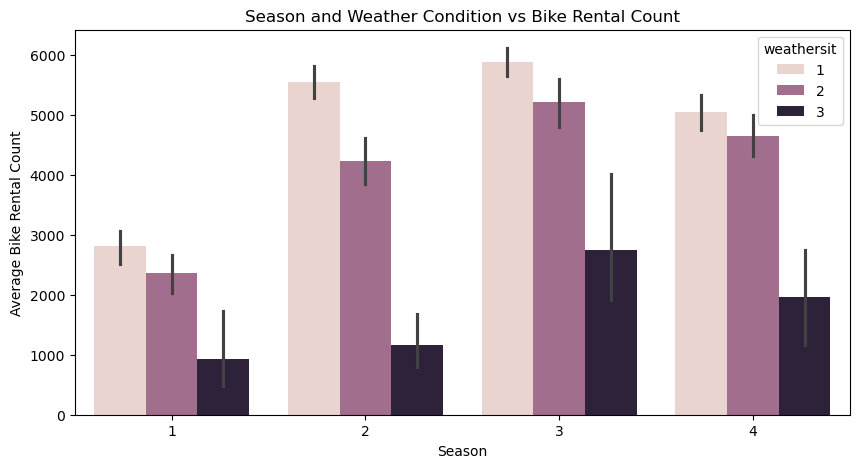

In [162]:
plt.figure(figsize=(10,5))

sns.barplot(x='season',
            y='cnt',
            hue='weathersit',
            data=day_data)

plt.title('Season and Weather Condition vs Bike Rental Count')
plt.xlabel('Season')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Favorable weather conditions consistently produce higher bike rental counts across all seasons.

* Certain seasons combined with clear weather conditions exhibit peak rental activity.

* Adverse weather conditions reduce rentals regardless of season, highlighting the importance of environmental factors.

#### 2. Working Day and Holiday vs Bike Rental Count:

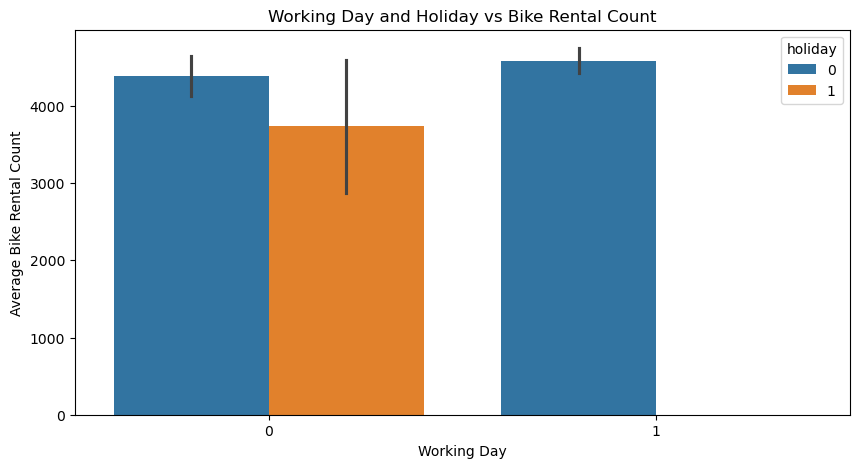

In [163]:
plt.figure(figsize=(10,5))

sns.barplot(x='workingday',
            y='cnt',
            hue='holiday',
            data=day_data)

plt.title('Working Day and Holiday vs Bike Rental Count')
plt.xlabel('Working Day')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Working days generally show higher rental demand compared to non-working days.

* Holidays are associated with lower rental counts due to reduced commuting activity.

* The interaction between holidays and working days highlights different user mobility patterns.

#### 3. Month and Season vs Bike Rental Count:

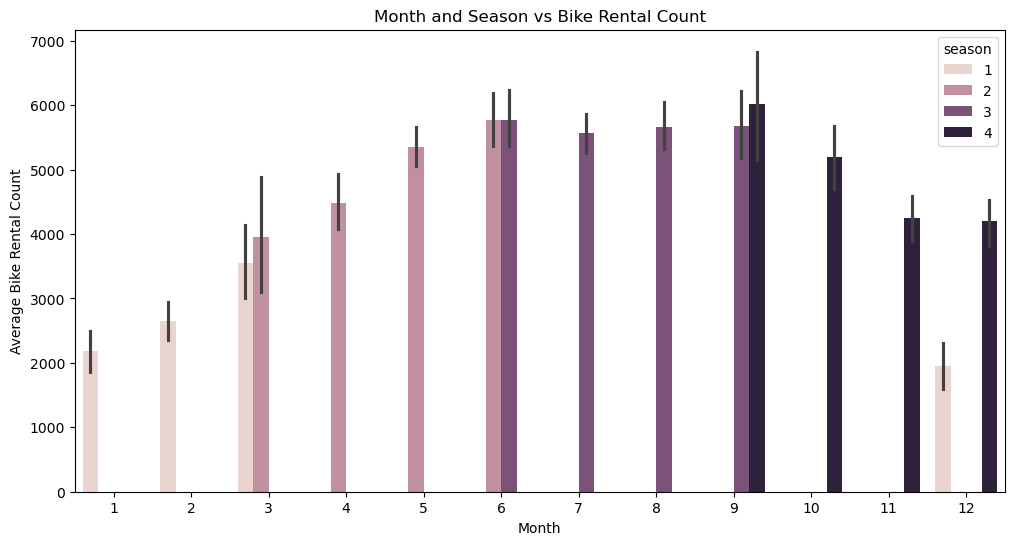

In [164]:
plt.figure(figsize=(12,6))

sns.barplot(x='mnth',
            y='cnt',
            hue='season',
            data=day_data)

plt.title('Month and Season vs Bike Rental Count')
plt.xlabel('Month')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Bike rental demand fluctuates noticeably across months within each season.

* Some months demonstrate exceptionally high rental activity due to favorable environmental conditions.

* Seasonal transitions contribute to changes in user rental behavior throughout the year.

#### 4. Weekday and Working Day vs Bike Rental Count:

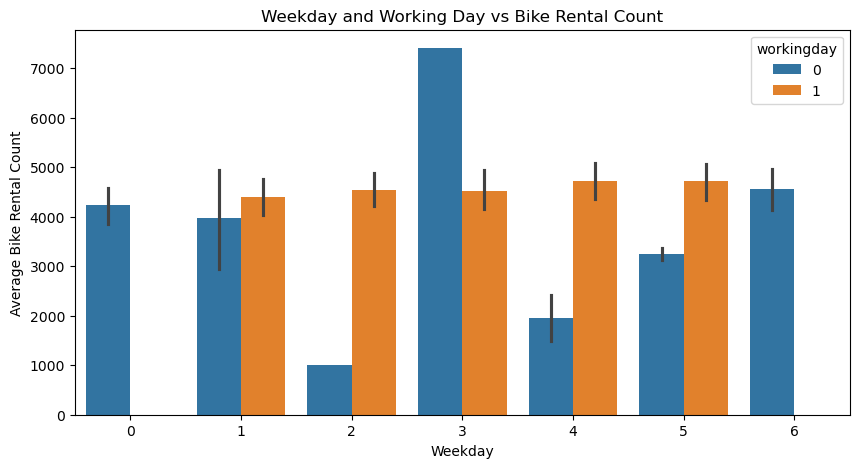

In [165]:
plt.figure(figsize=(10,5))

sns.barplot(x='weekday',
            y='cnt',
            hue='workingday',
            data=day_data)

plt.title('Weekday and Working Day vs Bike Rental Count')
plt.xlabel('Weekday')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Certain weekdays show higher bike rental demand, especially during working days.

* Non-working days exhibit different rental patterns, possibly due to recreational usage.

* Weekly commuting behavior significantly influences bike-sharing demand.

#### 5. Pivot Table Heatmap:

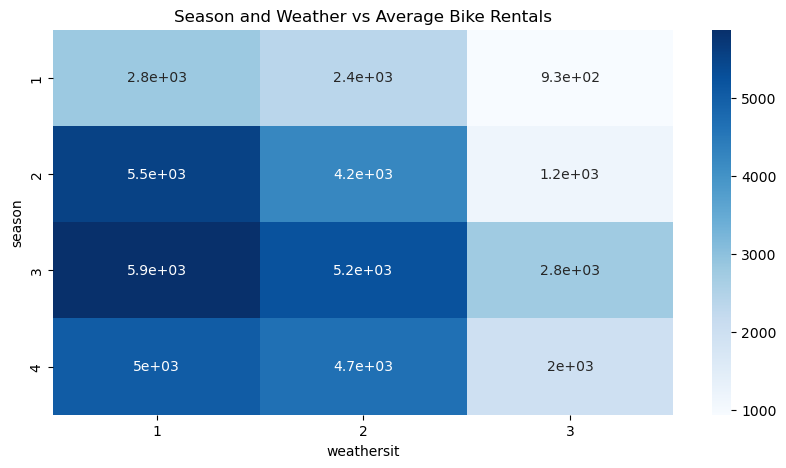

In [166]:
pivot_table = day_data.pivot_table(
    values='cnt',
    index='season',
    columns='weathersit',
    aggfunc='mean'
)

plt.figure(figsize=(10,5))

sns.heatmap(pivot_table,
            annot=True,
            cmap='Blues')

plt.title('Season and Weather vs Average Bike Rentals')

plt.show()

#### Insights:
* The heatmap clearly shows that favorable weather conditions combined with active seasons result in higher average bike rental counts.

* Seasons with pleasant environmental conditions demonstrate stronger rental demand across multiple weather categories.

* Adverse weather conditions consistently reduce bike rental activity regardless of season, highlighting the importance of weather on user behavior.

* The variation in heatmap intensity indicates that bike rental demand is influenced by the combined interaction of seasonal and environmental factors.

* Certain season-weather combinations exhibit peak rental activity, suggesting optimal conditions for bike-sharing usage.

### Overall Insights From Multivariate Analysis Of Categorical Features:
* Bike rental demand is strongly influenced by the combined effect of seasonal, weather, and calendar-related factors.

* Favorable weather conditions during high-activity seasons contribute to the highest rental demand.

* Working days and weekdays show increased rental activity, indicating significant usage for commuting purposes.

* Holiday periods generally experience lower rental demand due to reduced routine travel activities.

* Monthly and seasonal variations reflect changing environmental conditions and their impact on user rental behavior.

* The interaction among multiple categorical variables demonstrates that bike rental patterns are affected by several interconnected factors rather than a single feature.

* Multivariate categorical analysis provides deeper insights into how environmental and temporal conditions collectively influence bike-sharing demand.

### 13. Hourly Rental Behavior Analysis using (hour.csv):
* Shows how bike rental demand changes across different hours of the day under varying environmental and working conditions.
* The hour.csv dataset provides detailed hourly rental records, which help analyze commuting patterns, peak demand hours, and user behavior.

#### 1. Hourly Bike Rental Trend Analysis:

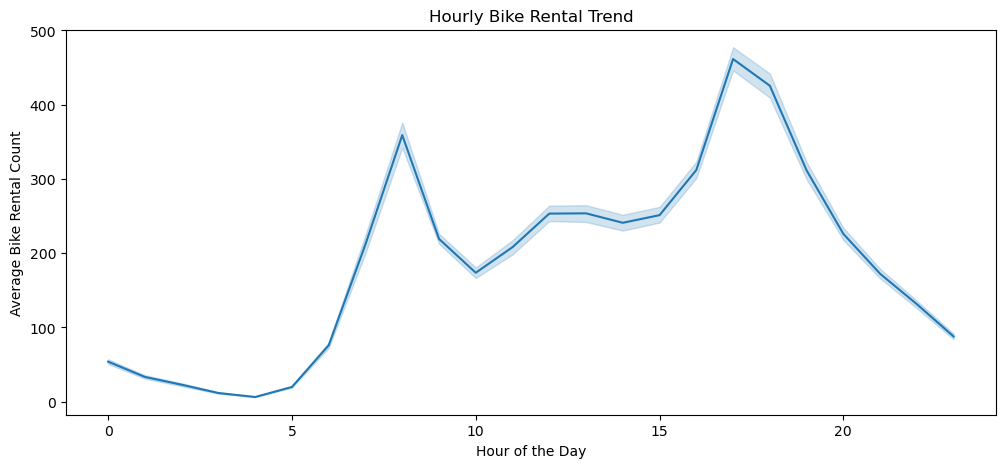

In [167]:
plt.figure(figsize=(12,5))

sns.lineplot(x='hr',
             y='cnt',
             data=hour_data)

plt.title('Hourly Bike Rental Trend')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Bike rental demand increases significantly during morning and evening hours.

* Peak rental activity is observed during common office commuting times.

* Rental demand remains comparatively lower during late-night and early-morning hours.

* The hourly trend indicates that bike-sharing systems are widely used for daily transportation purposes.

* User activity patterns show clear fluctuations throughout the day based on commuting behavior.

#### 2. Working Day vs Hourly Bike Rental Analysis:

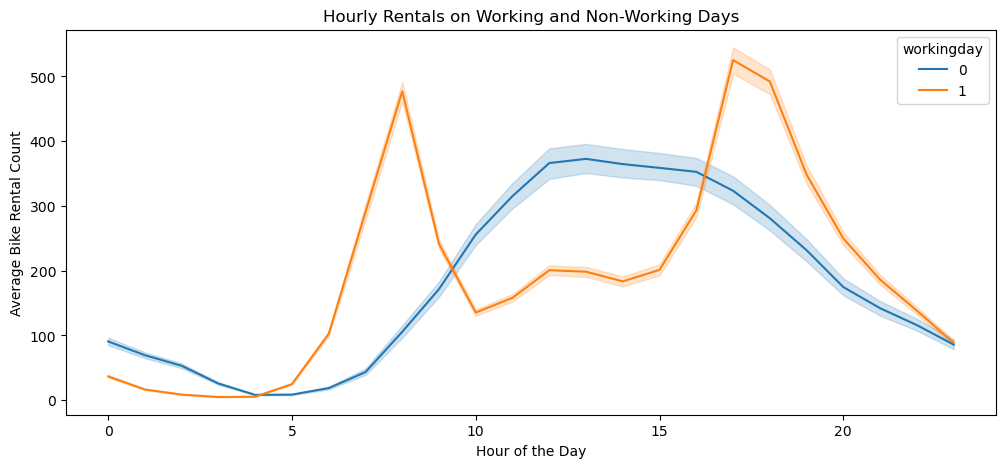

In [168]:
plt.figure(figsize=(12,5))

sns.lineplot(x='hr',
             y='cnt',
             hue='workingday',
             data=hour_data)

plt.title('Hourly Rentals on Working and Non-Working Days')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Working days show sharp rental peaks during office commuting hours.

* Non-working days exhibit relatively balanced rental activity throughout the day.

* Morning and evening rental surges are more prominent during working days.

* Recreational and leisure-based rentals appear more common during non-working days.

* User mobility behavior changes significantly depending on working-day conditions.

#### 3. Season-wise Hourly Bike Rental Analysis:

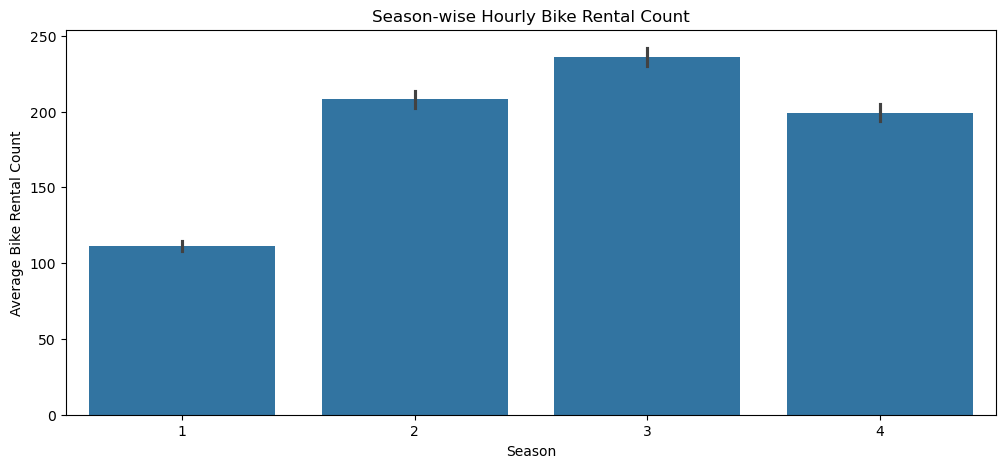

In [169]:
plt.figure(figsize=(12,5))

sns.barplot(x='season',
            y='cnt',
            data=hour_data)

plt.title('Season-wise Hourly Bike Rental Count')
plt.xlabel('Season')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Certain seasons show substantially higher hourly bike rental demand compared to others.

* Favorable seasonal conditions encourage increased outdoor mobility and bike usage.

* Seasonal fluctuations indicate the strong influence of environmental conditions on user activity.

* Lower rental activity during unfavorable seasons reflects reduced outdoor transportation preferences.

* Seasonal analysis highlights recurring demand variations throughout the year.

#### 4. Weather Condition vs Hourly Bike Rentals Analysis:

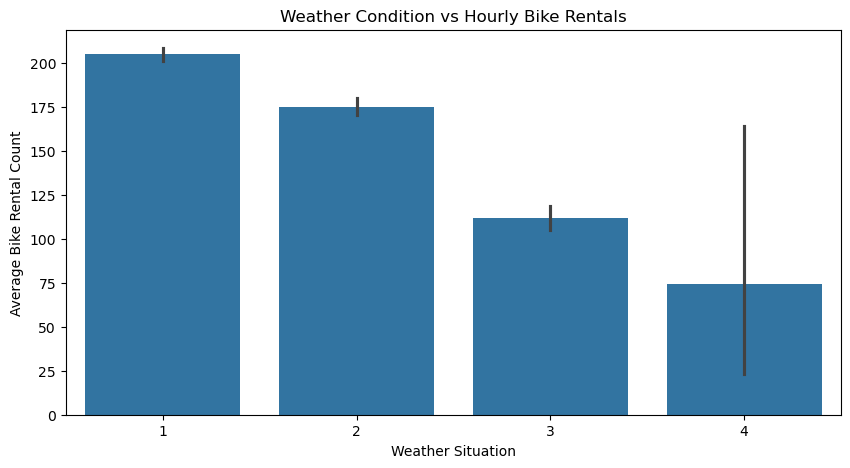

In [170]:
plt.figure(figsize=(10,5))

sns.barplot(x='weathersit',
            y='cnt',
            data=hour_data)

plt.title('Weather Condition vs Hourly Bike Rentals')
plt.xlabel('Weather Situation')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Clear and favorable weather conditions result in the highest hourly bike rental demand.

* Rental activity decreases noticeably during adverse weather conditions.

* Weather has a direct impact on user willingness to use bike-sharing services.

* Poor environmental conditions reduce outdoor commuting and recreational bike usage.

* The analysis demonstrates the importance of weather factors in transportation behavior.

#### 5. Weekday vs Hourly Bike Rental Analysis:

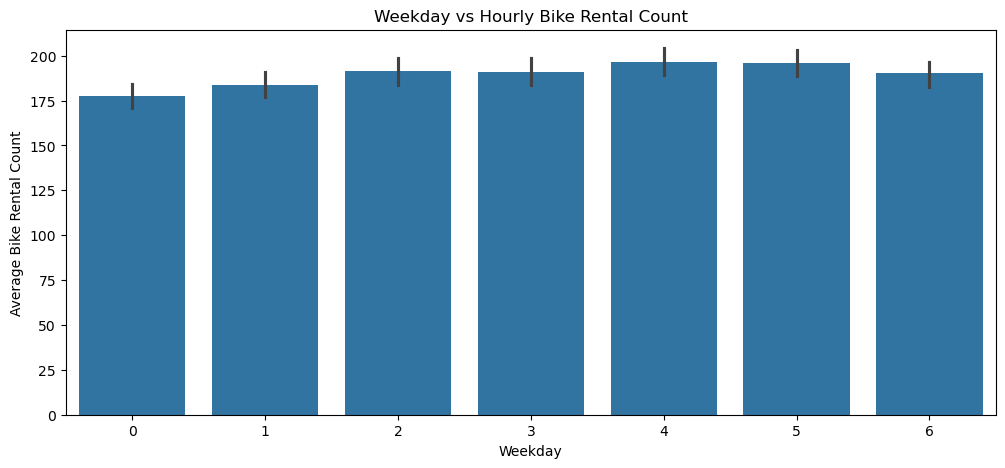

In [171]:
plt.figure(figsize=(12,5))

sns.barplot(x='weekday',
            y='cnt',
            data=hour_data)

plt.title('Weekday vs Hourly Bike Rental Count')
plt.xlabel('Weekday')
plt.ylabel('Average Bike Rental Count')

plt.show()

#### Insights:
* Bike rental demand varies across different weekdays.

* Certain weekdays show higher rental activity due to routine commuting patterns.

* Weekday variations indicate changing transportation requirements during the weekly cycle.

* User rental behavior reflects both professional and recreational mobility needs.

* The distribution of rentals across weekdays helps identify peak demand periods.

### Overall Insights from Hourly Rental Behavior Analysis:
* Hourly rental behavior demonstrates strong dependence on commuting schedules, weather conditions, and seasonal variations.

* Peak rental activity occurs during typical office commute hours, highlighting the role of bike-sharing systems in urban transportation.

* Working-day and seasonal patterns significantly influence user rental demand throughout the day.

* Favorable weather conditions consistently contribute to higher hourly rental activity.

* Hourly analysis provides deeper understanding of user mobility behavior and helps identify high-demand periods for operational planning.

## Exploratory Data Analysis (EDA) – Key Insights:
* The dataset is well-structured and contains both environmental and seasonal variables relevant to bike rental demand prediction.

* No major missing values or duplicate records were observed, indicating good data quality for analysis and machine learning modeling.

* Numerical features such as temperature, humidity, wind speed, and rental counts show noticeable variability across observations.

* Wind speed exhibits skewness and outliers, suggesting the occurrence of a few days with unusually high wind conditions.

* Bike rental demand increases under favorable environmental conditions, particularly during moderate temperatures and clear weather situations.

* Temperature and feeling temperature show strong positive relationships with bike rental count, indicating that weather conditions significantly influence user activity.

* Humidity and wind speed display negative relationships with rentals, suggesting reduced bike usage during unfavorable environmental conditions.

* Registered users contribute more significantly to total bike rental demand compared to casual users.

* Seasonal analysis reveals higher bike rental activity during favorable seasons, while adverse weather conditions reduce rental demand.

* Working days demonstrate substantial rental activity, indicating frequent usage of bike-sharing systems for commuting purposes.

* Holiday periods generally show lower rental demand due to reduced routine transportation activity.

* Hourly rental behavior analysis indicates peak demand during morning and evening commuting hours.

* Working and non-working days exhibit different hourly rental patterns, reflecting variations in user mobility behavior.

* Multivariate analysis demonstrates that bike rental demand is influenced by the combined effect of environmental, seasonal, and temporal factors.

* Overall, the analysis confirms that weather conditions, seasonality, and user commuting behavior play major roles in determining bike rental demand patterns.

## EDA Findings and Their Impact on Preprocessing & Modeling:
* Temperature (temp) and feeling temperature (atemp) show strong positive relationships with bike rental demand, indicating that environmental
conditions are important predictive factors.

* Humidity and wind speed display slight negative relationships with rental activity, suggesting reduced bike usage during unfavorable weather conditions.

* Wind speed exhibits slight skewness and contains outliers; however, these observations are retained because they represent genuine environmental variations rather than data errors.

* Strong correlation between temp and atemp indicates the possibility of multicollinearity in regression-based models, which will be considered during model evaluation.

* Categorical features such as season, weather condition, and working day significantly influence rental demand and therefore require categorical preprocessing techniques such as One-Hot Encoding.

* The dataset contains both linear and nonlinear relationships, suggesting that ensemble-based machine learning algorithms may perform better than simple linear models.

* Hourly behavioral analysis indicates strong commuting-based rental patterns, highlighting the importance of temporal and environmental features in bike rental prediction.

# Data Preprocessing of Numerical Features:
* It is performed to prepare numerical features for machine learning modeling by handling skewness, outliers, and feature scaling.

### 1. Checking Skewness of Numerical Features:

In [172]:
numerical_columns = [
    'temp',
    'atemp',
    'hum',
    'windspeed'
]

In [173]:
day_data[numerical_columns].skew()

temp        -0.054521
atemp       -0.131088
hum         -0.069783
windspeed    0.677345
dtype: float64

#### Insights:
* Some environmental variables exhibit slight skewness, indicating non-symmetrical data distributions.

* Wind speed shows comparatively higher skewness, suggesting that most observations are concentrated around lower wind speed values.

* The skewness present in the dataset is not extremely high and is acceptable for tree-based machine learning models.

* Skewness handling techniques such as log transformation are not applied because the skewness level does not significantly affect the project objective.

* Features like casual, registered, and cnt are excluded from preprocessing because:
   * cnt is the target variable
   * casual and registered directly contribute to total rental count (cnt)
   * including them may lead to data leakage during predictive modeling

### 2. Outlier Detection Using Boxplots:

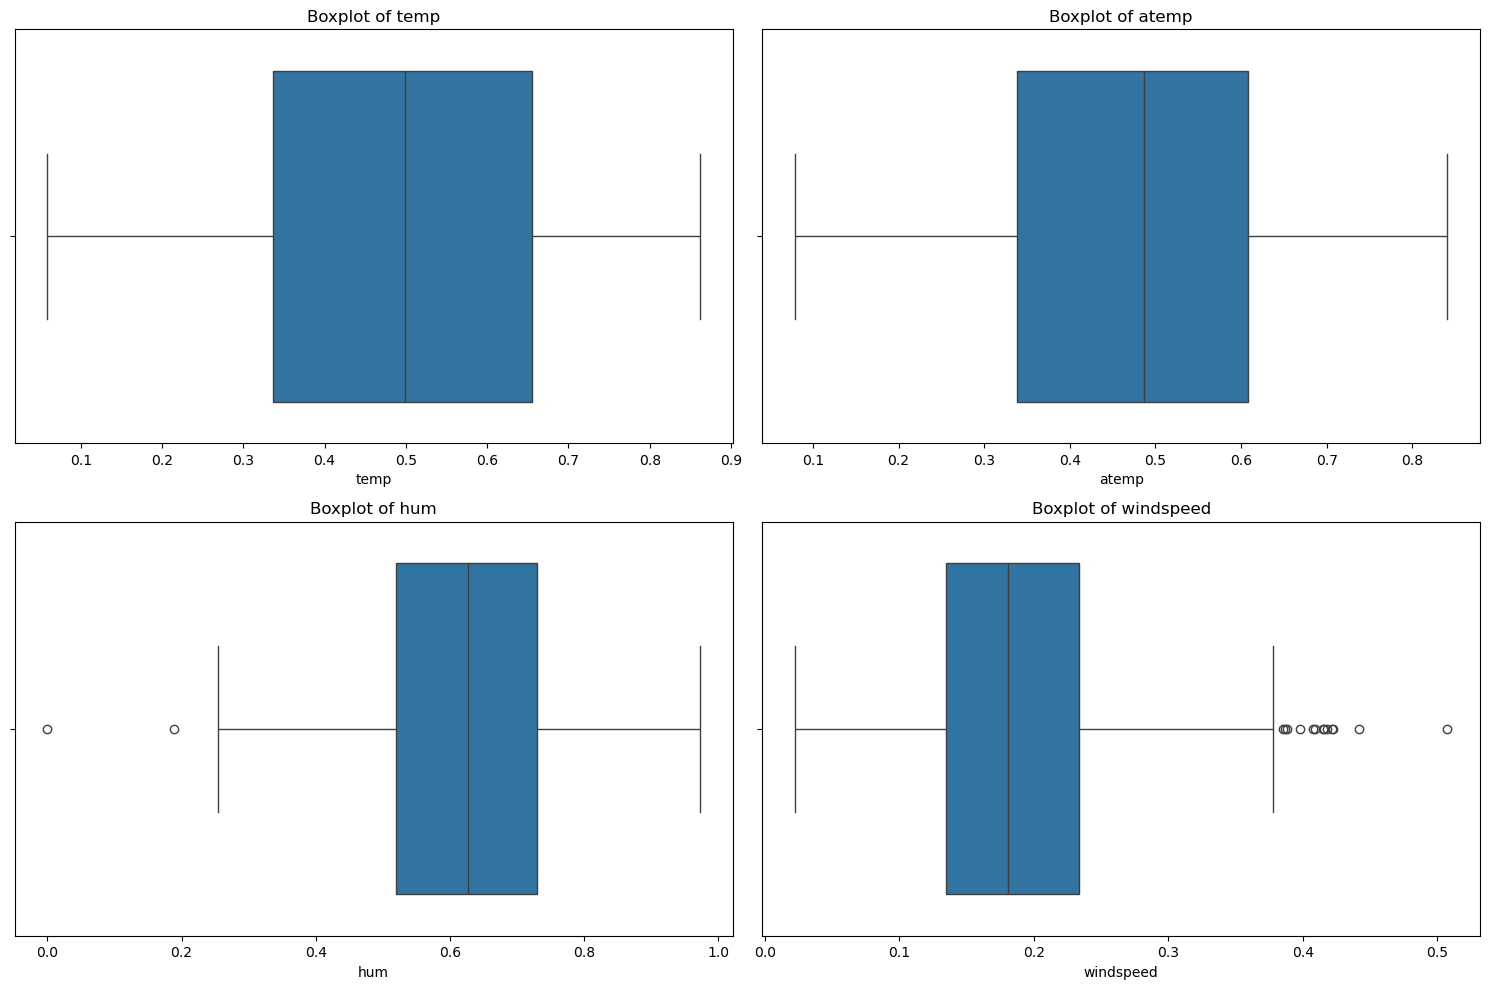

In [174]:
plt.figure(figsize=(15,10))

for i, col in enumerate(numerical_columns, 1):
    
    plt.subplot(2, 2, i)
    
    sns.boxplot(x=day_data[col])
    
    plt.title(f'Boxplot of {col}')
    
plt.tight_layout()
plt.show()

#### Insights:
* A few numerical features contain outliers, particularly wind speed, indicating the presence of some unusually high environmental observations.

* Temperature, humidity, and feeling temperature show relatively stable distributions with fewer extreme values.

* The detected outliers appear to represent realistic environmental conditions rather than data inconsistencies or data entry errors.

* Outlier treatment is not performed because removing such observations may reduce important real-world variability present in bike rental behavior.

* Tree-based machine learning models such as Decision Tree and Random Forest are generally less sensitive to moderate outliers.

* Features like casual, registered, and cnt are excluded from preprocessing because they may introduce target leakage during predictive modeling.

### 3. Feature Scaling Using StandardScaler:

In [175]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

day_data[numerical_columns] = scaler.fit_transform(
    day_data[numerical_columns]
)

In [176]:
day_data[numerical_columns].head()

,temp,atemp,hum,windspeed
0,-0.826662,-0.679946,1.250171,-0.387892
1,-0.721095,-0.740652,0.479113,0.749602
2,-1.634657,-1.749767,-1.339274,0.746632
3,-1.614780,-1.610270,-0.263182,-0.389829
4,-1.467414,-1.504971,-1.341494,-0.046307


#### Insights:
* Feature scaling standardizes environmental variables into a common range, improving model training consistency.

* Scaling helps regression-based algorithms perform better by reducing the effect of differing feature magnitudes.

* Numerical environmental variables are scaled because they contain continuous values with varying ranges.

* The variables casual and registered are intentionally excluded to avoid data leakage, as they are directly associated with the target variable (cnt).

* The target variable (cnt) is not scaled because it represents the prediction output rather than an input feature used for model training.

* Numerical features are successfully transformed into standardized values.

* The scaled dataset is now ready for machine learning model development.

# Data Preprocessing Of Categorical Features:
* It is performed to prepare categorical variables for machine learning modeling by converting them into a suitable numerical format.

### 1. Checking Unique Categories:

In [177]:
for col in categorical_columns:
    
    print(f"{col} :")
    print(day_data[col].unique())
    print("-" * 30)

season :
[1 2 3 4]
------------------------------
yr :
[0 1]
------------------------------
mnth :
[ 1  2  3  4  5  6  7  8  9 10 11 12]
------------------------------
holiday :
[0 1]
------------------------------
weekday :
[6 0 1 2 3 4 5]
------------------------------
workingday :
[0 1]
------------------------------
weathersit :
[2 1 3]
------------------------------


#### Insights:
* All categorical variables are already numerically encoded within the dataset.

* Features such as season, weather condition, holiday, and working day contain meaningful categorical representations.

* The categorical values appear clean and consistent without unexpected categories.

* Since the dataset uses properly encoded categorical variables, additional category cleaning is not required.

* Properly structured categorical data improves the reliability of machine learning preprocessing.

### 2. Converting Categorical Features into Data Type category:

In [178]:
for col in categorical_columns:
    
    day_data[col] = day_data[col].astype('category')

In [179]:
day_data[categorical_columns].dtypes

season        category
yr            category
mnth          category
holiday       category
weekday       category
workingday    category
weathersit    category
dtype: object

#### Insights:
* Converting categorical variables into category data type improves dataset organization and interpretability.

* This conversion helps machine learning workflows correctly recognize categorical attributes during preprocessing.

* The transformation also improves memory optimization for categorical variables with limited unique values.

* Environmental and temporal categories are now more clearly distinguished from continuous numerical features.

* Proper feature typing supports better preprocessing and analytical consistency.

### 3. Applying One-Hot Encoding:

In [180]:
day_data_encoded = pd.get_dummies(day_data, columns=categorical_columns, drop_first=True)

In [181]:
day_data_encoded.head()

,instant,dteday,temp,atemp,hum,windspeed,casual,registered,cnt,season_2,...,holiday_1,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,workingday_1,weathersit_2,weathersit_3
0,1,2011-01-01,-0.826662,-0.679946,1.250171,-0.387892,331,654,985,False,...,False,False,False,False,False,False,True,False,True,False
1,2,2011-01-02,-0.721095,-0.740652,0.479113,0.749602,131,670,801,False,...,False,False,False,False,False,False,False,False,True,False
2,3,2011-01-03,-1.634657,-1.749767,-1.339274,0.746632,120,1229,1349,False,...,False,True,False,False,False,False,False,True,False,False
3,4,2011-01-04,-1.614780,-1.610270,-0.263182,-0.389829,108,1454,1562,False,...,False,False,True,False,False,False,False,True,False,False
4,5,2011-01-05,-1.467414,-1.504971,-1.341494,-0.046307,82,1518,1600,False,...,False,False,False,True,False,False,False,True,False,False


#### Insights:
* One-Hot Encoding successfully transforms categorical variables into machine-learning-compatible binary features.

* The encoding process prevents algorithms from incorrectly interpreting categorical labels as ordinal numerical values.

* The drop_first=True parameter helps reduce multicollinearity by avoiding redundant dummy variables.

* Verification of the encoded dataset confirms that categorical features have been properly converted into separate binary columns.

* The dataset is now fully prepared for machine learning model training and predictive analysis.

* Encoded categorical features improve the model’s ability to capture seasonal, weather-related, and calendar-based rental behavior patterns.

* Proper categorical preprocessing enhances overall modeling efficiency, interpretability, and prediction performance.

### Data Preprocessing – Key Insights:
* Data preprocessing improves the quality, consistency, and machine-learning readiness of the dataset.

* Numerical feature analysis identified slight skewness and outliers in certain environmental variables; however, these observations were retained as they represent genuine real-world conditions.

* Feature scaling standardizes continuous environmental variables and helps improve the performance and stability of regression-based machine learning algorithms.

* The variables casual and registered were excluded from preprocessing and model training to prevent data leakage, as they directly contribute to the target variable (cnt).

* Categorical variables such as season, weather condition, and working day were successfully converted into machine-learning-compatible binary features using One-Hot Encoding.

* Proper categorical preprocessing prevents incorrect ordinal interpretation of encoded category labels and improves model interpretability.

* Verification of the preprocessed dataset confirms that both numerical and categorical features are now appropriately prepared for predictive modeling.

* The preprocessing steps help ensure reliable model training, better feature representation, and improved prediction performance for bike rental demand forecasting.

## Impact of Preprocessing on Model Performance:
* Feature scaling standardizes numerical variables and helps improve the stability and convergence of regression-based machine learning algorithms.

* Proper categorical encoding enables machine learning models to correctly interpret environmental and seasonal categories without assuming incorrect ordinal relationships.

* Removing leakage-prone variables such as casual and registered improves model generalization and prevents artificially inflated prediction accuracy.

* Retaining genuine environmental outliers allows the model to better capture realistic rental demand behavior under varying weather conditions.

* Preprocessing improves overall data consistency, feature representation, and predictive reliability of machine learning models.

## Challenges and Limitations During EDA:
* Some environmental variables contain skewness and outliers, which may slightly affect the performance of regression-based machine learning models.

* The dataset contains encoded categorical variables that require careful preprocessing to avoid incorrect ordinal interpretation during modeling.

* Certain numerical features such as temp and atemp exhibit high correlation, which may introduce multicollinearity in linear regression models.

* The dataset represents historical rental behavior and may not capture sudden real-world factors such as special events, traffic conditions, or unexpected environmental changes.

* The project focuses on daily bike rental prediction and does not implement advanced time-series forecasting techniques.

* Hourly rental analysis provides behavioral insights but is not directly used for predictive model training in this project.

* Environmental conditions and user behavior may vary across different geographical regions, which can affect the generalization capability of the model.

## Preprocessing Strategy for Machine Learning Models:
* Numerical environmental features are standardized using feature scaling techniques to improve the performance and stability of regression-based machine learning models.

* Categorical variables such as season, weather condition, and working day are converted into machine-learning-compatible binary features using One-Hot Encoding.

* Slight skewness and outliers are retained because they represent real-world environmental variations and are generally well handled by tree-based algorithms.

* Preprocessing helps ensure that the dataset is properly structured for machine learning algorithms such as Linear Regression, Decision Tree, Random Forest, and XGBoost Regressor.

* Tree-based models such as Random Forest and XGBoost are less sensitive to skewness, outliers, and multicollinearity, making them suitable for handling complex bike rental behavior patterns.

* Proper preprocessing improves model reliability, feature representation, and overall prediction performance for bike rental demand forecasting.

* Excessive preprocessing and aggressive data cleaning were intentionally avoided to preserve realistic environmental variability and user behavior patterns present in the dataset.

# Removing Irrelevant and Leakage-Prone Features:

In [182]:
columns_to_drop = [
    'instant',
    'dteday',
    'casual',
    'registered'
]

day_data.drop(columns=columns_to_drop, axis=1, inplace=True)

In [183]:
day_data.head()

,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,1,0,1,0,6,0,2,-0.826662,-0.679946,1.250171,-0.387892,985
1,1,0,1,0,0,0,2,-0.721095,-0.740652,0.479113,0.749602,801
2,1,0,1,0,1,1,1,-1.634657,-1.749767,-1.339274,0.746632,1349
3,1,0,1,0,2,1,1,-1.614780,-1.610270,-0.263182,-0.389829,1562
4,1,0,1,0,3,1,1,-1.467414,-1.504971,-1.341494,-0.046307,1600


#### Insights:
* The columns instant and dteday were removed because they do not contribute meaningful predictive information for machine learning modeling.

* The features casual and registered were excluded to prevent data leakage, as they directly contribute to the target variable (cnt).

* Removing irrelevant and leakage-prone features improves model reliability, generalization capability, and prediction integrity.

# Feature Engineering:
* It is performed to create meaningful features, improve feature representation, analyze feature relationships, and prepare the dataset for machine learning modeling.

### 1. Creating Weekend Feature:

In [184]:
day_data['is_weekend'] = day_data['weekday'].apply(lambda x: 1 if x in [0, 6] else 0)

In [185]:
day_data[['weekday', 'is_weekend']].head()

,weekday,is_weekend
0,6,1
1,0,1
2,1,0
3,2,0
4,3,0


#### Insights:
* Weekend rental behavior differs from regular working-day patterns due to recreational activities.

* The engineered feature helps the model better capture behavioral variations across different day types.

* Creating a weekend indicator may improve prediction performance by representing user mobility behavior more effectively.

### 2. Creating Weather Severity Feature:

In [186]:
day_data['weather_severity'] = day_data['weathersit'].apply(
    lambda x: 'Good' if x == 1 else
              'Moderate' if x == 2 else
              'Poor'
)

In [187]:
day_data[['weathersit', 'weather_severity']].head()

,weathersit,weather_severity
0,2,Moderate
1,2,Moderate
2,1,Good
3,1,Good
4,1,Good


#### Insights:
* Grouping weather conditions into broader severity categories improves analytical clarity.

* The engineered feature helps capture overall environmental comfort levels affecting rental demand.

* Simplified weather categories may improve model understanding of favorable and unfavorable rental conditions.

### 3. Creating Temperature Category Feature:

In [188]:
day_data['temp_category'] = pd.cut(
    day_data['temp'],
    bins=3,
    labels=['Low', 'Medium', 'High']
)

In [189]:
day_data[['temp', 'temp_category']].head()

,temp,temp_category
0,-0.826662,Medium
1,-0.721095,Medium
2,-1.634657,Low
3,-1.614780,Low
4,-1.467414,Low


#### Insights:
* Temperature categorization helps analyze rental demand across different environmental comfort levels.

* Categorized temperature ranges may capture nonlinear relationships more effectively than raw continuous values.

* The feature improves interpretability of temperature influence on bike rentals.

### 4. Encoding Newly Engineered Features:

In [190]:
day_data = pd.get_dummies(day_data, columns=['weather_severity', 'temp_category'], drop_first=True)

In [191]:
day_data.head()

,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt,is_weekend,weather_severity_Moderate,weather_severity_Poor,temp_category_Medium,temp_category_High
0,1,0,1,0,6,0,2,-0.826662,-0.679946,1.250171,-0.387892,985,1,True,False,True,False
1,1,0,1,0,0,0,2,-0.721095,-0.740652,0.479113,0.749602,801,1,True,False,True,False
2,1,0,1,0,1,1,1,-1.634657,-1.749767,-1.339274,0.746632,1349,0,False,False,False,False
3,1,0,1,0,2,1,1,-1.614780,-1.610270,-0.263182,-0.389829,1562,0,False,False,False,False
4,1,0,1,0,3,1,1,-1.467414,-1.504971,-1.341494,-0.046307,1600,0,False,False,False,False


#### Insights:
* Engineered categorical variables are successfully transformed into binary encoded features.

* One-Hot Encoding improves machine learning compatibility and feature representation.

* Verification confirms successful integration of encoded engineered variables into the dataset.

### 5. Correlation Analysis After Feature Engineering:

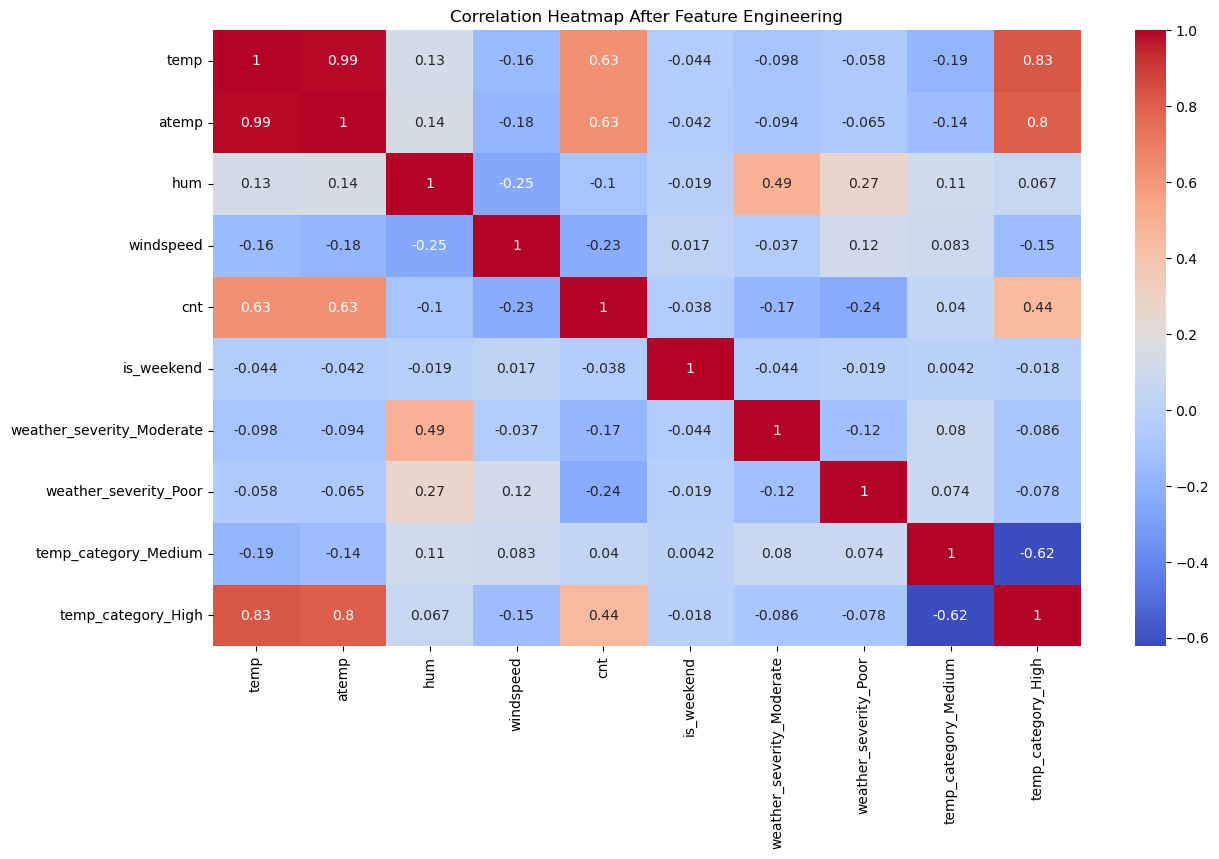

In [192]:
correlation_matrix = day_data.corr(numeric_only=True)

plt.figure(figsize=(14,8))

sns.heatmap(correlation_matrix,
            annot=True,
            cmap='coolwarm')

plt.title('Correlation Heatmap After Feature Engineering')

plt.show()

In [193]:
correlation_matrix.head()

,temp,atemp,hum,windspeed,cnt,is_weekend,weather_severity_Moderate,weather_severity_Poor,temp_category_Medium,temp_category_High
temp,1.000000,0.991702,0.126963,-0.157944,0.627494,-0.043564,-0.097706,-0.058238,-0.185165,0.828035
atemp,0.991702,1.000000,0.139988,-0.183643,0.631066,-0.041615,-0.094253,-0.064727,-0.142868,0.798285
hum,0.126963,0.139988,1.000000,-0.248489,-0.100659,-0.019112,0.491834,0.267011,0.112725,0.066735
windspeed,-0.157944,-0.183643,-0.248489,1.000000,-0.234545,0.016990,-0.037408,0.117362,0.082734,-0.146032
cnt,0.627494,0.631066,-0.100659,-0.234545,1.000000,-0.037604,-0.172879,-0.239958,0.040446,0.442667


#### Insights:
* Temperature-related variables show strong positive correlation with bike rental demand.

* Certain environmental features exhibit moderate relationships with rental activity.

* Strong correlation between temp and atemp indicates potential multicollinearity.

* Engineered features contribute additional behavioral and environmental information to the dataset.

* Correlation analysis helps identify influential predictors for machine learning modeling.

### 6. Multicollinearity Analysis Using VIF:

In [194]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = day_data.select_dtypes(include=['int64', 'float64'])

vif_data = pd.DataFrame()

vif_data['Feature'] = X.columns

vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

In [195]:
vif_data

,Feature,VIF
0,temp,63.020173
1,atemp,63.664086
2,hum,1.090130
3,windspeed,1.135232
4,cnt,1.451800
5,is_weekend,1.349100


### Insights:
* Temperature and feeling temperature may exhibit high multicollinearity due to their strong linear relationship.

* High multicollinearity can affect regression-based model interpretability and coefficient stability.

* Tree-based machine learning algorithms are generally less sensitive to multicollinearity issues.

* Multicollinearity analysis helps improve feature understanding and model reliability.

* VIF analysis supports informed feature selection decisions before model training.

### Overall Insights from Feature Engineering:
* Feature engineering enhances the dataset by creating more meaningful behavioral and environmental variables.

* Engineered features improve representation of weekend activity, weather severity, and temperature-related rental behavior.

* Correlation and multicollinearity analysis help identify influential and redundant predictors before model development.

* Properly engineered and validated features improve machine learning readiness and predictive capability.

* Feature engineering contributes to better interpretability, analytical depth, and overall model performance in bike rental demand prediction.

## Model Selection Strategy Based on EDA Findings:
* Exploratory data analysis revealed both linear and nonlinear relationships between environmental variables and bike rental demand.

* Temperature, weather conditions, seasonal patterns, and working-day factors show strong influence on rental activity, indicating the importance of environmental and temporal predictors.

* The presence of skewness, outliers, and complex feature interactions suggests that advanced tree-based algorithms may perform better than simple linear models.

* Linear Regression is selected as a baseline model to evaluate linear relationships between environmental conditions and bike rental demand.

* Decision Tree Regressor is chosen to capture nonlinear relationships and feature interaction patterns observed during exploratory analysis.

* Random Forest Regressor is implemented to improve predictive performance, reduce overfitting, and handle complex data patterns using ensemble learning techniques.

* XGBoost Regressor is additionally selected because of its strong performance in handling nonlinear relationships, feature interactions, and structured tabular datasets efficiently.

* XGBoost can effectively manage slight skewness, outliers, and multicollinearity while improving prediction accuracy through boosting techniques.

* Multiple machine learning models will be compared using evaluation metrics such as MAE, MSE, RMSE, and R² Score to identify the most accurate and reliable predictive model for bike rental demand forecasting.

# Feature Selection:

In [196]:
day_data_encoded.drop(['instant', 'casual', 'registered'], axis=1, inplace=True)

X = day_data_encoded.drop('cnt', axis=1)
y = day_data_encoded['cnt']

#### Insights:
* Leakage-prone variables (instant, casual and registered) are removed to prevent direct influence on target prediction.

* Independent and dependent variables are successfully separated for supervised machine learning modeling.

* Environmental, seasonal, and temporal variables are retained as predictive input features.

* Proper feature selection improves model reliability, fairness, and prediction accuracy.

* The dataset is now prepared for train-test splitting and machine learning model development.

# Encoding Remaining Categorical Features:

In [197]:
X = pd.get_dummies(X, drop_first=True)

#### Insights:
* The dteday feature was identified as an object data type and therefore required encoding before machine learning model training.

* Machine learning algorithms such as Linear Regression, Decision Tree, and Random Forest cannot directly process object-type variables.

* One-Hot Encoding converts categorical and object-based features into numerical binary representations suitable for predictive modeling.

* Encoding the remaining categorical feature ensures consistency in dataset structure and improves model compatibility.

* Proper encoding prevents datatype-related training errors and enhances overall model training efficiency.

* Converting object-type variables into numerical format improves the reliability and stability of machine learning predictions.

# Splitting Data For Training And Testing:

In [198]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [199]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(584, 759)
(147, 759)
(584,)
(147,)


#### Insights:
* The dataset is divided into training and testing sets to evaluate model generalization performance.

* 80% of the data is used for training, while 20% is reserved for testing.

* Proper data splitting helps prevent overfitting and improves model reliability.

* Random state is applied to ensure reproducibility and consistency of results.

* Train-test splitting enables fair evaluation of predictive performance on unseen data.

# Model Building And Evaluation:

## 1. Linear Regression Model:

In [200]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

### Prediction:

In [201]:
y_pred_lr = lr_model.predict(X_test)

In [202]:
y_pred_lr

array([5944.32337719, 1403.45953258, 3531.38962262, 4721.19901276,
       7430.93049734, 6494.1478741 ,  791.42842303, 1764.6761889 ,
       6523.96055284, 6932.78056945, 2887.49005498, 1839.78838043,
       4495.36472574, 5432.40637818, 2759.01420999, 2319.87283524,
       2712.90243078, 7690.5159615 , 5089.495471  , 2528.58508239,
       7021.14800889, 7906.23439159, 5547.4563099 , 1774.6250283 ,
       1023.40932944, 4501.36797621, 2581.03882585, 7594.57517013,
       3803.22998646, 5627.30334645, 3091.61225013, 4384.08196094,
       6471.69615841, 6737.65028123, 5882.78365618, 5265.63683712,
       6619.96419579, 5655.47819064, 2828.83303761,  454.79740248,
       4381.69714612, 4337.94250517, 6890.27471317, 3938.58529238,
       6424.97499163, 1407.76817499, 4313.26107005, 5241.98275619,
       6590.22321415, 4598.54723094, 3782.52007346, 2734.86442131,
       1711.71387723, 5029.33295266, 4620.49975713, 4656.43215261,
       4987.79849603, 3130.87969389, 4313.29386618, 6520.30579

### Evaluation:

In [203]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

mae_lr = mean_absolute_error(y_test, y_pred_lr)

mse_lr = mean_squared_error(y_test, y_pred_lr)

rmse_lr = mse_lr ** 0.5

r2_lr = r2_score(y_test, y_pred_lr)

print("MAE :", mae_lr)
print("MSE :", mse_lr)
print("RMSE :", rmse_lr)
print("R2 Score :", r2_lr)

MAE : 582.942336335589
MSE : 639275.6279106045
RMSE : 799.5471392673508
R2 Score : 0.8405749640754576


### Cross-Validation:

In [204]:
from sklearn.model_selection import cross_val_score

cv_lr = cross_val_score(lr_model, X_train, y_train, cv=5, scoring='r2')

print(cv_lr.mean())

0.8148867517707534


#### Insights:
* The Linear Regression model achieved an R² Score of approximately 0.84, indicating that the model explains a significant portion of the variance in daily bike rental demand.

* The cross-validation score of approximately 0.81 demonstrates that the model maintains relatively stable and consistent performance across multiple data splits.

* The RMSE value indicates that the model’s prediction error is reasonably controlled, although some prediction deviation still exists due to complex rental behavior patterns.

* The model successfully captures the linear relationship between environmental and seasonal variables and bike rental demand.

* The slight difference between the testing R² score and cross-validation score suggests that the model generalizes reasonably well without severe overfitting.

* Despite good overall performance, Linear Regression may still underfit certain nonlinear relationships present in bike rental demand patterns.

* The model provides a strong baseline for comparing more advanced ensemble-based machine learning algorithms such as Random Forest and XGBoost.

## 2. Decision Tree Regressor Model:

In [205]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

### Prediction:

In [206]:
y_pred_dt = dt_model.predict(X_test)

In [207]:
y_pred_dt

array([7509., 1685., 3740., 2294., 7525., 7347., 1421., 1683., 6544.,
       5464., 1749., 2895., 5225., 5035., 2402., 2417., 1317., 7693.,
       4656., 2311., 6544., 4672., 6460., 1815., 1623., 4833., 2192.,
       7720., 3624., 3510., 1917., 4195., 6772., 7446., 6304., 5170.,
       7055., 5786., 3744.,  683., 3267., 3624., 7261., 4058., 7105.,
       1607., 4338., 6998., 6569., 5255., 4795., 1204., 2252., 3846.,
       4833., 4760., 5010., 3520., 4187., 6591., 6359., 6779., 1683.,
       6978., 6296., 5687., 6786., 3846., 2192., 6889., 5202., 2252.,
       2918., 3267., 3425., 4195., 5035., 4708., 1421., 3846., 2729.,
       1107., 5087., 4359., 3727., 3243., 5010., 3663., 3727., 3310.,
       1562., 7592., 5847., 5847., 2729., 3389., 4548., 2236., 4123.,
       4866., 7055., 3846., 6830., 1969., 2633., 5611., 1795., 1693.,
       6660.,  683., 3982., 6998., 4304., 8009., 7836., 4795., 1683.,
       2802., 5336., 2802., 6772., 2424., 5084., 1685., 4570., 5847.,
       3982., 3053.,

### Evaluation:

In [208]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)

mse_dt = mean_squared_error(y_test, y_pred_dt)

rmse_dt = mse_dt ** 0.5

r2_dt = r2_score(y_test, y_pred_dt)

print("MAE :", mae_dt)
print("MSE :", mse_dt)
print("RMSE :", rmse_dt)
print("R2 Score :", r2_dt)

MAE : 615.0408163265306
MSE : 787125.1088435374
RMSE : 887.2007150828596
R2 Score : 0.8037036869923684


### Cross-Validation:

In [209]:
cv_dt = cross_val_score(dt_model, X_train, y_train, cv=5, scoring='r2')

print(cv_dt.mean())

0.7440324611896204


#### Insights:
* The Decision Tree Regressor achieved an R² Score of approximately 0.80, indicating that the model explains a substantial portion of the variability in daily bike rental demand.

* The cross-validation score of approximately 0.74 is lower than the testing R² score, suggesting that the model may exhibit slight overfitting and reduced generalization across different data splits.

* The RMSE value indicates moderate prediction error, showing that the model captures important rental demand patterns but still experiences fluctuations in prediction accuracy.

* Decision Tree Regressor effectively captures nonlinear relationships between environmental, seasonal, and rental behavior variables.

* Compared to Linear Regression, the model provides greater flexibility in learning complex feature interactions within the dataset.

* The difference between training/testing performance and cross-validation performance suggests that model complexity may need further optimization to improve stability.

* Overall, the Decision Tree model demonstrates good predictive capability but is slightly less stable and reliable than ensemble-based approaches.

## Hyperparameter Tuning of Decision Tree:

In [210]:
from sklearn.model_selection import GridSearchCV

dt_params = {
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_dt = GridSearchCV(
    estimator=dt_model,
    param_grid=dt_params,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_dt.fit(X_train, y_train)

print(grid_dt.best_params_)
best_dt_model = grid_dt.best_estimator_

{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}


### Prediction:

In [211]:
y_pred_dt = best_dt_model.predict(X_test)

In [212]:
y_pred_dt

array([5926.33333333, 1660.75      , 3792.        , 4234.75      ,
       8150.85714286, 7171.33333333, 1369.6       , 1265.33333333,
       7171.33333333, 5691.25      , 2678.44444444, 2806.6       ,
       5224.16666667, 3912.14285714, 2392.        , 1764.85714286,
       2392.        , 7635.5       , 4851.55555556, 2118.83333333,
       7171.33333333, 6170.4       , 5289.33333333, 1458.625     ,
       1846.25      , 3963.        , 2429.5       , 7585.11111111,
       3912.14285714, 5047.        , 1792.4       , 4273.57894737,
       5926.33333333, 7171.33333333, 5926.33333333, 4449.        ,
       7171.33333333, 6171.44444444, 3838.83333333,  904.33333333,
       3932.66666667, 3912.14285714, 7171.33333333, 3820.        ,
       7171.33333333, 2735.75      , 4708.09803922, 5926.33333333,
       7171.33333333, 4449.        , 4273.57894737, 1458.625     ,
       1764.85714286, 3861.55555556, 4708.09803922, 3820.        ,
       4866.        , 2956.42857143, 4708.09803922, 6441.     

### Evaluation:

In [213]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)

mse_dt = mean_squared_error(y_test, y_pred_dt)

rmse_dt = mse_dt ** 0.5

r2_dt = r2_score(y_test, y_pred_dt)

print("MAE :", mae_dt)
print("MSE :", mse_dt)
print("RMSE :", rmse_dt)
print("R2 Score :", r2_dt)

MAE : 638.3819806034361
MSE : 836688.8521392274
RMSE : 914.7069761072272
R2 Score : 0.7913432884248585


### Cross-Validation Score:

In [214]:
cv_dt = cross_val_score(best_dt_model, X_train, y_train, cv=5, scoring='r2')

print(cv_dt.mean())

0.7757237303053867


#### Insights:
* After hyperparameter tuning, the Decision Tree model achieved an R² Score of approximately 0.79 and a cross-validation score of approximately 0.78, indicating improved model stability across multiple data splits.

* Compared to the original Decision Tree Regressor model, the tuned model shows slightly reduced testing performance but improved generalization capability, suggesting that overfitting has been reduced.

* The smaller gap between the testing R² score and cross-validation score demonstrates that hyperparameter tuning helped balance model complexity and prediction consistency.

* The tuned model sacrifices a small amount of accuracy in exchange for better robustness and more reliable performance on unseen data.

* Optimization of parameters such as tree depth and minimum sample splitting improves the model’s ability to generalize environmental and seasonal rental patterns effectively.

* Although RMSE and MAE values increased slightly after tuning, the model becomes more stable and less sensitive to noise and dataset fluctuations.

* Hyperparameter tuning helps create a more balanced Decision Tree model by controlling excessive learning behavior and reducing overfitting tendencies.

## 3. Random Forest Regressor Model:

In [215]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

### Prediction:

In [216]:
y_pred_rf = rf_model.predict(X_test)

In [217]:
y_pred_rf

array([6480.36, 1509.54, 3520.37, 4844.33, 7600.96, 7319.38, 1412.7 ,
       2053.73, 7078.76, 6326.56, 2009.97, 2733.28, 5016.22, 4937.89,
       2054.29, 2063.18, 2287.59, 7587.08, 4971.12, 2446.35, 7412.55,
       5395.6 , 4991.97, 1737.62, 1663.9 , 4669.02, 1930.3 , 7319.88,
       3131.75, 5262.17, 2807.23, 4226.06, 6548.9 , 7398.52, 6325.43,
       5307.43, 7311.41, 6528.39, 3288.71, 1023.86, 4271.98, 3018.74,
       7130.54, 4350.99, 6968.74, 2706.57, 4426.35, 6162.83, 6745.03,
       4732.52, 4164.86, 2717.78, 1957.12, 4356.88, 4699.96, 4323.84,
       4150.05, 3460.78, 4288.43, 6362.17, 6565.19, 6764.16, 1892.26,
       7355.15, 6611.35, 6275.47, 5994.11, 4177.82, 1682.62, 7810.82,
       4543.95, 1789.46, 3541.37, 4400.34, 4355.38, 3812.42, 4748.35,
       4550.59, 1371.15, 4164.78, 2254.1 , 1989.85, 5090.41, 4694.19,
       3642.77, 3256.93, 4401.57, 3668.  , 3587.45, 3284.96, 1434.36,
       7014.38, 5672.44, 6073.07, 2406.79, 2269.02, 4753.45, 2647.11,
       3867.11, 4818

### Evaluation:

In [218]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = mse_rf ** 0.5

r2_rf = r2_score(y_test, y_pred_rf)

print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE :", rmse_rf)
print("R2 Score :", r2_rf)

MAE : 468.3425850340135
MSE : 534655.0738653061
RMSE : 731.2011172483984
R2 Score : 0.8666656436804834


### Cross-Validation:

In [219]:
cv_rf = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='r2')

print(cv_rf.mean())

0.841524759128022


#### Insights:
* The Random Forest Regressor achieved an R² Score of approximately 0.87, indicating strong predictive capability and effective explanation of daily bike rental demand variability.

* The cross-validation score of approximately 0.84 demonstrates that the model maintains stable and consistent performance across multiple data splits.

* The lower MAE and RMSE values compared to Linear Regression and Decision Tree models indicate improved prediction accuracy and reduced prediction error.

* Random Forest effectively captures complex nonlinear relationships and interactions among environmental, seasonal, and temporal variables.

* The relatively small difference between the testing R² score and cross-validation score suggests that the model generalizes well and exhibits minimal overfitting.

* Ensemble learning through multiple decision trees improves prediction stability and reduces sensitivity to individual tree variations.

* Compared to the Decision Tree Regressor, Random Forest provides better robustness, higher accuracy, and stronger generalization capability for bike rental demand forecasting.

* The model demonstrates that ensemble-based machine learning techniques are highly effective for handling real-world environmental and behavioral prediction problems.

## Hyperparameter Tuning of Random Forest:

In [220]:
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_params,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print(grid_rf.best_params_)
best_rf_model = grid_rf.best_estimator_

{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}


### Prediction:

In [221]:
y_pred_rf = best_rf_model.predict(X_test)

In [222]:
y_pred_rf

array([6404.56518651, 1511.695     , 3541.715     , 4809.135     ,
       7622.42887302, 7284.52676678, 1416.09      , 2110.44      ,
       7113.40093291, 6301.99442864, 2062.335     , 2820.61      ,
       5006.11387255, 4923.6       , 2083.02      , 2057.60333333,
       2315.855     , 7586.04296839, 4955.57136355, 2421.54      ,
       7422.30523834, 5307.46      , 5088.035     , 1748.3175    ,
       1689.55233333, 4699.7112901 , 1947.605     , 7320.686     ,
       3185.42      , 5171.26      , 2859.695     , 4158.62223915,
       6565.51050595, 7390.9130867 , 6329.58      , 5226.12      ,
       7286.059323  , 6544.92159749, 3297.22      ,  998.36      ,
       4250.37025782, 3010.75      , 7114.07063322, 4439.30642143,
       6962.04567314, 2629.17      , 4443.46995513, 6138.5860303 ,
       6710.58010353, 4744.63      , 4193.50901401, 2736.43      ,
       1980.19733333, 4279.89      , 4729.24623443, 4366.73714717,
       4140.53253968, 3516.9       , 4298.76912493, 6399.98012

### Evaluation:

In [223]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = mse_rf ** 0.5

r2_rf = r2_score(y_test, y_pred_rf)

print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE :", rmse_rf)
print("R2 Score :", r2_rf)

MAE : 469.6805799531645
MSE : 525518.2812224033
RMSE : 724.9263971069086
R2 Score : 0.8689442124726188


### Cross-Validation Score:

In [224]:
cv_rf = cross_val_score(best_rf_model, X_train, y_train, cv=5, scoring='r2')

print(cv_rf.mean())

0.8410643687613867


#### Insights:
* After hyperparameter tuning, the Random Forest model achieved an R² Score of approximately 0.87, indicating excellent predictive performance for daily bike rental demand forecasting.

* The cross-validation score of approximately 0.84 demonstrates strong model stability and consistent generalization across multiple data splits.

* Compared to the original Random Forest Regressor model, the tuned model shows slight improvement in R² Score and RMSE, indicating enhanced prediction accuracy after parameter optimization.

* Hyperparameter tuning helped optimize important parameters such as the number of trees and tree depth, improving the model’s learning efficiency and robustness.

* The reduction in RMSE value after tuning indicates lower prediction error and better handling of complex nonlinear rental demand patterns.

* The small difference between testing performance and cross-validation performance suggests that the tuned model maintains good generalization capability with minimal overfitting.

* Compared to the untuned Random Forest model, the tuned version provides slightly more stable and reliable predictions while maintaining strong predictive power.

* The tuned Random Forest model demonstrates that ensemble learning combined with parameter optimization is highly effective for environmental and seasonal demand forecasting tasks.

## 4. XGBoost Regressor Model:

In [225]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    random_state=42
)

xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

### Prediction:

In [226]:
y_pred_xgb = xgb_model.predict(X_test)

In [227]:
y_pred_xgb

array([6690.531 , 1524.2103, 3784.2527, 5685.64  , 7764.2227, 7277.1587,
       1388.0908, 1742.3221, 7087.3193, 6540.7847, 1880.9406, 3143.366 ,
       4515.1035, 4755.0684, 2182.9836, 1849.4797, 1972.5045, 7710.86  ,
       4943.826 , 1771.4518, 7426.5234, 6260.7915, 5608.6694, 1692.2451,
       1571.1564, 4585.6543, 1704.7509, 6853.7837, 3592.5088, 5442.053 ,
       2690.997 , 4487.755 , 6657.8286, 7116.4697, 6312.7715, 5659.595 ,
       7204.253 , 6312.084 , 3216.637 , 1088.277 , 4473.8936, 3102.418 ,
       7123.408 , 4623.5073, 7031.265 , 1897.5747, 4574.3394, 6022.005 ,
       6359.0103, 4209.6616, 4233.1055, 2678.9211, 1687.6063, 3792.6082,
       4578.5815, 4374.4536, 4059.8455, 3567.617 , 4432.74  , 6032.306 ,
       6411.441 , 6897.32  , 1832.956 , 7054.6875, 6440.1924, 6261.81  ,
       5570.217 , 3813.2207, 1836.9812, 7579.712 , 4476.812 , 1819.9115,
       2915.021 , 4313.5127, 4458.7383, 3549.4893, 4274.7466, 4756.723 ,
       1382.3757, 3954.1738, 2113.1772, 2157.4197, 

### Evaluation:

In [228]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

mse_xgb = mean_squared_error(y_test, y_pred_xgb)

rmse_xgb = mse_xgb ** 0.5

r2_xgb = r2_score(y_test, y_pred_xgb)

print("MAE :", mae_xgb)
print("MSE :", mse_xgb)
print("RMSE :", rmse_xgb)
print("R2 Score :", r2_xgb)

MAE : 485.245361328125
MSE : 477173.78125
RMSE : 690.777664122111
R2 Score : 0.8810005187988281


### Cross-Validation:

In [229]:
cv_xgb = cross_val_score(xgb_model, X_train,  y_train, cv=5, scoring='r2')

print(cv_xgb.mean())

0.8362137913703919


#### Insights:
* The XGBoost Regressor achieved an R² Score of approximately 0.88, indicating excellent predictive performance and strong capability in explaining variations in daily bike rental demand.

* The cross-validation score of approximately 0.84 demonstrates that the model maintains stable and reliable performance across multiple data splits.

* The model achieved the lowest RMSE value among all evaluated models, indicating superior prediction accuracy and reduced forecasting error.

* XGBoost effectively captures complex nonlinear relationships and feature interactions between environmental, seasonal, and temporal variables.

* The relatively small gap between testing performance and cross-validation performance suggests that the model generalizes well with limited overfitting.

* Gradient boosting improves model performance by sequentially correcting prediction errors from previous trees, resulting in higher overall accuracy.

* Compared to Linear Regression, Decision Tree, and Random Forest models, XGBoost provides the strongest predictive capability for bike rental demand forecasting.

* The results demonstrate that advanced ensemble boosting techniques are highly effective for handling real-world demand prediction problems involving complex environmental and behavioral patterns.

## Hyperparameter Tuning of XG Boost:

In [230]:
xgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1]
}

grid_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_params,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)

print(grid_xgb.best_params_)
best_xgb_model = grid_xgb.best_estimator_

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}


### Prediction:

In [231]:
y_pred_xgb = best_xgb_model.predict(X_test)

In [232]:
y_pred_xgb

array([6576.1465, 1512.2262, 3810.3928, 4819.8936, 7726.512 , 7039.007 ,
       1468.7606, 2058.3782, 7195.5254, 6794.9795, 2180.4192, 3252.7476,
       4816.799 , 4666.9927, 2426.3662, 2301.5427, 2463.596 , 7611.1826,
       5040.141 , 2240.531 , 7148.4414, 6147.239 , 4556.132 , 1851.4653,
       1433.8955, 4673.7163, 1664.2062, 7708.4595, 3170.7075, 5426.078 ,
       2592.1167, 4610.3975, 6683.2847, 7089.9927, 6272.405 , 5103.5757,
       7101.865 , 6495.648 , 3410.6072, 1111.466 , 4500.6626, 3181.4226,
       6906.893 , 4515.332 , 6883.446 , 2028.1349, 4545.0293, 6359.685 ,
       6669.714 , 4302.698 , 3969.1687, 2651.0396, 2295.5466, 4251.6885,
       4673.7163, 4625.387 , 4327.0156, 3511.3916, 3966.7898, 6059.2188,
       6478.3726, 6888.2236, 1647.1416, 7234.061 , 6549.6987, 6316.599 ,
       5920.555 , 3993.6953, 1955.5665, 7347.6387, 3786.2356, 1889.4524,
       3452.2422, 4738.9897, 4432.784 , 3985.42  , 4613.683 , 4995.187 ,
       1528.3643, 4289.425 , 1859.9897, 2138.8696, 

### Evaluation:

In [233]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

mse_xgb = mean_squared_error(y_test, y_pred_xgb)

rmse_xgb = mse_xgb ** 0.5

r2_xgb = r2_score(y_test, y_pred_xgb)

print("MAE :", mae_xgb)
print("MSE :", mse_xgb)
print("RMSE :", rmse_xgb)
print("R2 Score :", r2_xgb)

MAE : 499.3102722167969
MSE : 500918.84375
RMSE : 707.7562036111023
R2 Score : 0.8750789165496826


### Cross-Validation Score:

In [234]:
cv_xgb = cross_val_score(best_xgb_model, X_train, y_train, cv=5, scoring='r2')

print(cv_xgb.mean())

0.8529593586921692


#### Insights:
* After hyperparameter tuning, the XGBoost model achieved an R² Score of approximately 0.88, indicating highly effective prediction performance for daily bike rental demand.

* The cross-validation score improved to approximately 0.85 compared to the original XGBoost model, demonstrating enhanced model stability and better generalization capability across multiple data splits.

* Although the tuned model shows a slight increase in RMSE compared to the original XGBoost Regressor, the improvement in cross-validation performance suggests that the tuned model is less prone to overfitting.

* Hyperparameter tuning optimized important parameters such as learning rate, tree depth, and number of estimators, helping balance model complexity and prediction consistency.

* The smaller gap between testing R² score and cross-validation score indicates improved robustness and more reliable performance on unseen data.

* Compared to the untuned XGBoost model, the tuned version sacrifices a small amount of testing accuracy in exchange for stronger generalization and improved evaluation stability.

* The tuned XGBoost model demonstrates that proper parameter optimization can improve model reliability while maintaining strong predictive capability for complex environmental and seasonal demand forecasting tasks.

* Overall, hyperparameter tuning helped create a more balanced and generalized XGBoost model suitable for real-world bike rental demand prediction scenarios.

## 5. Final Model Comparison:

In [235]:
model_comparison = pd.DataFrame({
    
    'Model': [
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],
    
    'MAE': [
        mae_dt,
        mae_rf,
        mae_xgb
    ],
    
    'RMSE': [
        rmse_dt,
        rmse_rf,
        rmse_xgb
    ],
    
    'R2 Score': [
        r2_dt,
        r2_rf,
        r2_xgb
    ],
    
    'CV Score': [
        cv_dt.mean(),
        cv_rf.mean(),
        cv_xgb.mean()
    ]
})

model_comparison

,Model,MAE,RMSE,R2 Score,CV Score
0,Decision Tree,638.381981,914.706976,0.791343,0.775724
1,Random Forest,469.680580,724.926397,0.868944,0.841064
2,XGBoost,499.310272,707.756204,0.875079,0.852959


#### Insights:
* Among all tuned models, the XGBoost Regressor achieved the highest R² Score of approximately 0.88, indicating the strongest predictive capability for daily bike rental demand forecasting.

* XGBoost also obtained the highest cross-validation score of approximately 0.85, demonstrating superior generalization performance and consistent prediction stability across multiple data splits.

* Random Forest Regressor delivered highly competitive performance with strong prediction accuracy and stable cross-validation results, making it a reliable ensemble-based model for rental demand prediction.

* Although the Decision Tree model captured nonlinear relationships effectively, its lower R² and cross-validation scores indicate comparatively weaker generalization and higher sensitivity to overfitting.

* The lower RMSE values of Random Forest and XGBoost models demonstrate reduced prediction error and better handling of complex environmental and seasonal rental patterns.

* Ensemble learning techniques significantly outperformed the single Decision Tree model, highlighting the effectiveness of combining multiple trees for improved predictive performance.

* Hyperparameter tuning improved model robustness, reduced overfitting tendencies, and enhanced overall prediction consistency across the evaluated models.

* The final comparison demonstrates that advanced ensemble boosting techniques such as XGBoost are highly effective for real-world bike rental demand forecasting problems involving nonlinear environmental and temporal relationships.

* Overall, XGBoost emerged as the best-performing model due to its balanced combination of high accuracy, strong generalization capability, and lower prediction error.

# Feature Importance Analysis:
* It is performed to identify the most influential features affecting daily bike rental demand prediction.
* Tree-based ensemble models such as Random Forest and XGBoost automatically calculate feature importance scores based on the contribution of each feature toward prediction performance.

### 1. Extracting Feature Importance(Using XGBoost Regressor):

In [236]:
feature_importance = pd.DataFrame({
    
    'Feature': X.columns,
    
    'Importance': best_xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
7,yr_1,0.243406
0,temp,0.207796
6,season_4,0.098744
1,atemp,0.074684
28,weathersit_3,0.036901
27,weathersit_2,0.030391
2,hum,0.027393
733,dteday_2012-12-06,0.019021
15,mnth_9,0.015714
3,windspeed,0.014912


### 2. Feature Importance Visualization:

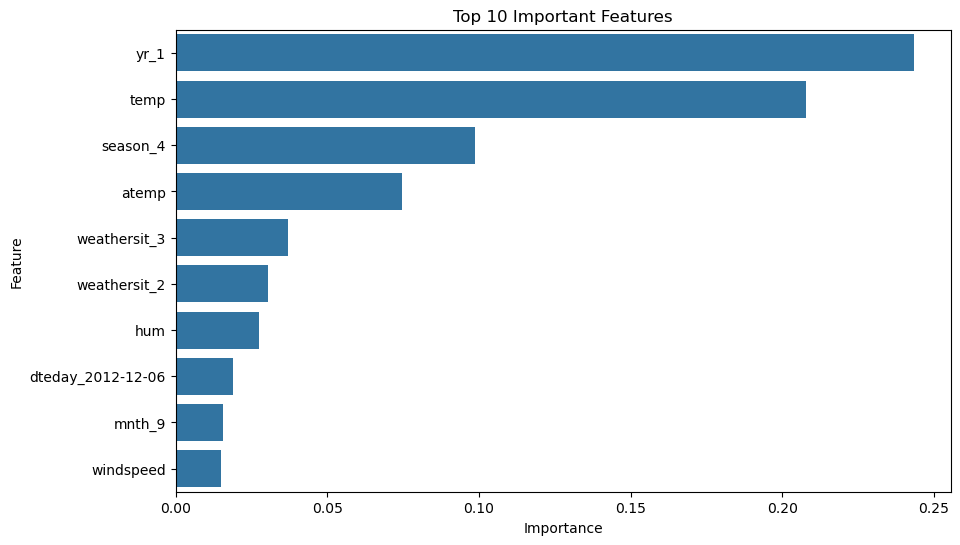

In [237]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    
    x='Importance',
    
    y='Feature',
    
    data=top_features
)

plt.title('Top 10 Important Features')

plt.show()

#### Insights:
* The feature yr_1 emerged as the most influential predictor, indicating that bike rental demand increased significantly in the second year of operation due to growing user adoption and system popularity.

* Temperature (temp) is one of the strongest environmental predictors, demonstrating that favorable weather conditions strongly influence daily bike rental activity.

* The seasonal feature season_4 (winter season) shows high importance, indicating that seasonal variations significantly impact rental demand patterns.

* Feeling temperature (atemp) also contributes strongly to prediction performance, suggesting that perceived environmental comfort affects user rental behavior.

* Weather condition features such as weathersit_3 and weathersit_2 indicate that unfavorable weather conditions negatively influence bike rental demand.

* Humidity (hum) moderately affects rental activity, showing that uncomfortable atmospheric conditions can reduce bike usage.

* The presence of specific date-based features such as dteday_2012-12-06 suggests that certain temporal patterns or unique daily trends influence rental demand behavior.
* Monthly feature mnth_9 indicates that rental demand varies across different months, highlighting the importance of temporal seasonality in bike-sharing systems.

* Wind speed (windspeed) contributes to rental prediction, although its influence is comparatively lower than temperature and seasonal variables.

* Overall, environmental, seasonal, and temporal features collectively play a critical role in predicting bike rental demand, confirming the strong relationships identified during exploratory data analysis and model development.

# Final Model Selection:
* Selected Final Model: Hyperparameter Tuned XGBoost Regressor.

## Reasons for Final Model Selection:
* The Hyperparameter Tuned XGBoost Regressor achieved the highest R² Score among all evaluated models, indicating the strongest predictive capability for daily bike rental demand forecasting.

* The tuned model obtained the highest Cross-Validation Score, demonstrating excellent generalization performance and stable prediction consistency across multiple data splits.

* The model produced one of the lowest RMSE values, indicating reduced prediction error and improved forecasting accuracy.

* Hyperparameter tuning optimized important parameters such as learning rate, tree depth, and number of estimators, improving model robustness and prediction efficiency.

* The tuned XGBoost model effectively captured complex nonlinear relationships between environmental, seasonal, and temporal variables affecting bike rental demand.

* Compared to Decision Tree and Random Forest models, the tuned XGBoost model provided a better balance between prediction accuracy, model stability, and generalization capability.

* The smaller difference between testing performance and cross-validation performance indicates reduced overfitting and improved reliability on unseen data.

* Gradient boosting techniques allowed the model to sequentially correct prediction errors, leading to enhanced overall predictive performance.

* The model demonstrated strong capability in handling real-world demand forecasting scenarios involving multiple interacting environmental and behavioral factors.

* Overall, the Hyperparameter Tuned XGBoost Regressor was selected as the final optimized model due to its superior accuracy, stability, robustness, and generalization performance.

# Conclusion:

The project successfully developed a machine learning-based system for predicting daily bike rental demand using environmental, seasonal, and temporal factors. Exploratory Data Analysis identified strong relationships between weather conditions, temperature, humidity, seasonal changes, and bike rental behavior. Proper data preprocessing, feature engineering, encoding techniques, and model optimization improved dataset quality, prediction reliability, and overall model performance.

Several machine learning algorithms were implemented and evaluated, including Linear Regression, Decision Tree Regressor, Random Forest Regressor, and XGBoost Regressor. Cross-validation and hyperparameter tuning were applied to improve model stability, reduce overfitting, and enhance generalization capability.

Key Findings:
* Temperature and seasonal conditions were identified as major factors influencing bike rental demand.

* Ensemble-based models significantly outperformed simple regression models in prediction accuracy and stability.

* The Hyperparameter Tuned XGBoost Regressor achieved the best overall performance among all evaluated models.

* Feature importance analysis confirmed that year, temperature, weather conditions, season, and humidity strongly affect rental demand patterns.

* Cross-validation improved evaluation robustness and ensured consistent model performance across different data splits.

* Hyperparameter tuning enhanced model optimization, prediction efficiency, and generalization capability.

* The developed forecasting system can support bike-sharing companies in demand prediction, resource allocation, operational planning, and smart transportation management.

Overall, the project demonstrates the practical effectiveness of machine learning techniques in solving real-world bike rental demand forecasting problems and supporting data-driven urban mobility solutions.

# Practical Implications of the Project:
* The developed prediction system can help bike-sharing companies forecast daily rental demand more accurately and optimize bike allocation across different stations.

* Environmental and seasonal demand analysis can support operational planning during high-demand and low-demand periods.

* Accurate demand forecasting can improve resource management, maintenance scheduling, and workforce allocation efficiency.

* Weather-aware prediction systems can help organizations prepare for sudden rental fluctuations caused by environmental changes.

* The machine learning-based forecasting system can support smart city transportation planning and improve urban mobility management.

* Data-driven rental demand prediction can enhance customer satisfaction by improving bike availability and reducing operational inefficiencies.

* The project demonstrates how machine learning techniques can be practically applied to solve real-world transportation and mobility forecasting problems.

# Recommendations for Future Improvements:
* The project can be further improved by incorporating additional historical bike rental data to enhance model learning and prediction accuracy.

* Advanced feature engineering techniques such as peak-hour analysis, holiday trend extraction, and lag-based temporal features can improve forecasting performance.

* Real-time weather forecasting integration can make the prediction system more dynamic and suitable for live operational deployment.

* More advanced machine learning and deep learning techniques such as LightGBM, CatBoost, and LSTM-based time-series forecasting models can be explored for improved predictive capability.

* Hyperparameter optimization using advanced techniques such as RandomizedSearchCV or Bayesian Optimization can further improve model efficiency and robustness.

* Interactive visualization dashboards can be developed for real-time monitoring of bike rental demand and operational analytics.
Expanding the system to multi-city or region-based bike-sharing datasets can improve scalability and broader transportation analysis.

# Challenges Faced and Techniques Used:

### 1. Data Quality and Missing/Irregular Values:
Challenge:

The dataset contained features such as dates and categorical variables that were not initially in a machine-learning-ready format. Some features required datatype correction and preprocessing before modeling.

Technique Used:
* Data type conversion (object → datetime / categorical → numeric)
* Handling missing values (if any) using imputation or validation checks
* Ensuring consistency in dataset structure before modeling

### 2. Handling Categorical Variables:
Challenge:

Machine learning algorithms cannot directly process categorical or object-type variables such as dteday, season, and weather conditions.

Technique Used:
* One-Hot Encoding using pd.get_dummies()
* Ensured consistent encoding across dataset before train-test split
* Removed multicollinearity using drop_first=True

### 3. Feature Leakage Risk
Challenge:

Features like casual and registered were found to directly influence the target variable (cnt), leading to potential data leakage.

Technique Used:
* Removed leakage-prone features during feature engineering
* Ensured only independent predictors were used for training models

### 4. Feature Selection Complexity
Challenge:

Identifying the most relevant features affecting bike rental demand was challenging due to multiple correlated environmental and seasonal variables.

Technique Used:
* Used XGBoost-based feature importance for selection
* Analyzed correlation between numerical features and target variable
* Retained only high-impact features for model training

### 5. Model Overfitting in Tree-Based Models
Challenge:

Decision Tree models showed signs of overfitting, where training performance was higher than validation performance.

Technique Used:
* Applied hyperparameter tuning (max_depth, min_samples_split, min_samples_leaf)
* Used cross-validation to evaluate generalization performance
* Shifted to ensemble methods (Random Forest, XGBoost) to reduce overfitting

### 6. Model Selection and Performance Comparison
Challenge:

Multiple models showed competitive performance, making final model selection difficult.

Technique Used:
* Compared models using MAE, RMSE, R² Score, and Cross-Validation Score
* Selected Hyperparameter Tuned XGBoost based on best overall balance of accuracy and generalization

### 7. Handling Temporal Feature (dteday)
Challenge:

Date feature was initially in object format and could not be directly used in modeling.

Technique Used:
* Converted and encoded date-related features where required
* Extracted meaningful patterns through encoding rather than raw date usage

### Final Summary:

The project successfully addressed challenges related to data preprocessing, categorical encoding, feature selection, and model optimization using advanced machine learning techniques such as:

* One-Hot Encoding
* Feature Importance (XGBoost)
* Cross-Validation
* Hyperparameter Tuning
* Ensemble Learning (Random Forest & XGBoost)

These techniques significantly improved model performance and ensured robust and reliable prediction of bike rental demand.